# **Problem Statement**

## Business Context

Renewable energy sources play an increasingly important role in the global energy mix, as the effort to reduce the environmental impact of energy production increases.

Out of all the renewable energy alternatives, wind energy is one of the most developed technologies worldwide. The U.S Department of Energy has put together a guide to achieving operational efficiency using predictive maintenance practices.

Predictive maintenance uses sensor information and analysis methods to measure and predict degradation and future component capability. The idea behind predictive maintenance is that failure patterns are predictable and if component failure can be predicted accurately and the component is replaced before it fails, the costs of operation and maintenance will be much lower.

The sensors fitted across different machines involved in the process of energy generation collect data related to various environmental factors (temperature, humidity, wind speed, etc.) and additional features related to various parts of the wind turbine (gearbox, tower, blades, break, etc.).

## Objective

“ReneWind” is a company working on improving the machinery/processes involved in the production of wind energy using machine learning and has collected data of generator failure of wind turbines using sensors. They have shared a ciphered version of the data, as the data collected through sensors is confidential (the type of data collected varies with companies). Data has 40 predictors, 20000 observations in the training set and 5000 in the test set.

The objective is to build various classification models, tune them, and find the best one that will help identify failures so that the generators could be repaired before failing/breaking to reduce the overall maintenance cost.
The nature of predictions made by the classification model will translate as follows:

- True positives (TP) are failures correctly predicted by the model. These will result in repairing costs.
- False negatives (FN) are real failures where there is no detection by the model. These will result in replacement costs.
- False positives (FP) are detections where there is no failure. These will result in inspection costs.

It is given that the cost of repairing a generator is much less than the cost of replacing it, and the cost of inspection is less than the cost of repair.

“1” in the target variables should be considered as “failure” and “0” represents “No failure”.

## Data Description

The data provided is a transformed version of the original data which was collected using sensors.

- Train.csv - To be used for training and tuning of models.
- Test.csv - To be used only for testing the performance of the final best model.

Both the datasets consist of 40 predictor variables and 1 target variable.

# **Installing and Importing the necessary libraries**

In [ ]:
# Installing the libraries with the specified version
!pip install --no-deps tensorflow==2.19.0 scikit-learn==1.6.1 matplotlib===3.10.0 seaborn==0.13.2 numpy==2.0.2 pandas==2.2.2 -q --user --no-warn-script-location

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, f1_score,accuracy_score, recall_score, precision_score, classification_report
from sklearn.utils import class_weight

import matplotlib.pyplot as plt

import time

import tensorflow
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dense, Input, Dropout,BatchNormalization
from tensorflow.keras import backend

# **Loading the Data**

In [ ]:
# uncomment and run the following lines for Google Colab
from google.colab import drive
drive.mount('/content/drive')
train_data_set = pd.read_csv('/......Train.csv')
test_data_set = pd.read_csv('/...../Test.csv')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Data Overview**

In [ ]:
# check the 5 first rows of the data set
train_data_set.head(10)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-4.464606,-4.679129,3.101546,0.506130,-0.221083,-2.032511,-2.910870,0.050714,-1.522351,3.761892,...,3.059700,-1.690440,2.846296,2.235198,6.667486,0.443809,-2.369169,2.950578,-3.480324,0
1,3.365912,3.653381,0.909671,-1.367528,0.332016,2.358938,0.732600,-4.332135,0.565695,-0.101080,...,-1.795474,3.032780,-2.467514,1.894599,-2.297780,-1.731048,5.908837,-0.386345,0.616242,0
2,-3.831843,-5.824444,0.634031,-2.418815,-1.773827,1.016824,-2.098941,-3.173204,-2.081860,5.392621,...,-0.257101,0.803550,4.086219,2.292138,5.360850,0.351993,2.940021,3.839160,-4.309402,0
3,1.618098,1.888342,7.046143,-1.147285,0.083080,-1.529780,0.207309,-2.493629,0.344926,2.118578,...,-3.584425,-2.577474,1.363769,0.622714,5.550100,-1.526796,0.138853,3.101430,-1.277378,0
4,-0.111440,3.872488,-3.758361,-2.982897,3.792714,0.544960,0.205433,4.848994,-1.854920,-6.220023,...,8.265896,6.629213,-10.068689,1.222987,-3.229763,1.686909,-2.163896,-3.644622,6.510338,0
5,0.159623,-4.233781,-0.264310,-5.477119,-0.190854,-0.356274,-0.134486,4.066608,-3.858569,1.692441,...,3.227235,0.628900,-1.548860,1.321979,5.461345,1.109410,-3.869993,0.273964,2.805941,0
6,-0.184565,-4.721470,0.864988,-3.078695,-2.226888,-1.282220,-0.804717,3.289733,-1.567971,0.749904,...,-0.544941,-0.762921,0.815558,1.889373,3.624347,1.555740,-5.432884,0.678703,0.464697,0
7,1.734840,1.682945,-1.269070,4.600630,-1.416975,-2.543916,0.131648,-0.198661,3.094057,-1.109324,...,1.717474,-3.838931,1.569448,1.794899,-4.268517,-0.516195,-0.619218,-0.830889,-4.967266,1
8,1.781583,1.314664,4.248690,-0.518293,-0.149044,0.033082,-1.087893,-3.117561,0.624935,1.567455,...,1.611014,2.951390,-1.862016,4.389598,1.371300,-2.516235,0.770496,0.831132,-2.310953,0
9,-0.894140,4.011498,5.251902,3.320747,0.727067,-4.771070,1.031232,3.632080,-1.391444,-1.966746,...,-0.635742,-4.449139,2.296340,1.575110,1.376268,0.596757,-1.413652,0.543871,0.035020,0


In [ ]:
# checking test data set
test_data_set.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-0.613489,-3.819640,2.202302,1.300420,-1.184929,-4.495964,-1.835817,4.722989,1.206140,-0.341909,...,2.291204,-5.411388,0.870073,0.574479,4.157191,1.428093,-10.511342,0.454664,-1.448363,0
1,0.389608,-0.512341,0.527053,-2.576776,-1.016766,2.235112,-0.441301,-4.405744,-0.332869,1.966794,...,-2.474936,2.493582,0.315165,2.059288,0.683859,-0.485452,5.128350,1.720744,-1.488235,0
2,-0.874861,-0.640632,4.084202,-1.590454,0.525855,-1.957592,-0.695367,1.347309,-1.732348,0.466500,...,-1.318888,-2.997464,0.459664,0.619774,5.631504,1.323512,-1.752154,1.808302,1.675748,0
3,0.238384,1.458607,4.014528,2.534478,1.196987,-3.117330,-0.924035,0.269493,1.322436,0.702345,...,3.517918,-3.074085,-0.284220,0.954576,3.029331,-1.367198,-3.412140,0.906000,-2.450889,0
4,5.828225,2.768260,-1.234530,2.809264,-1.641648,-1.406698,0.568643,0.965043,1.918379,-2.774855,...,1.773841,-1.501573,-2.226702,4.776830,-6.559698,-0.805551,-0.276007,-3.858207,-0.537694,0


Observation

---


We can see the variables has positive and negative numbers and the target as mention in the description has 0 and 1

# **Exploratory Data Analysis**

In [ ]:
# check the dimension of data set
train_data_set.shape

(20000, 41)

In [ ]:
test_data_set.shape

(5000, 41)

In [ ]:
#check data types
train_data_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22

In [ ]:
test_data_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      4995 non-null   float64
 1   V2      4994 non-null   float64
 2   V3      5000 non-null   float64
 3   V4      5000 non-null   float64
 4   V5      5000 non-null   float64
 5   V6      5000 non-null   float64
 6   V7      5000 non-null   float64
 7   V8      5000 non-null   float64
 8   V9      5000 non-null   float64
 9   V10     5000 non-null   float64
 10  V11     5000 non-null   float64
 11  V12     5000 non-null   float64
 12  V13     5000 non-null   float64
 13  V14     5000 non-null   float64
 14  V15     5000 non-null   float64
 15  V16     5000 non-null   float64
 16  V17     5000 non-null   float64
 17  V18     5000 non-null   float64
 18  V19     5000 non-null   float64
 19  V20     5000 non-null   float64
 20  V21     5000 non-null   float64
 21  V22     5000 non-null   float64
 22  

In [ ]:
# convert target to float
train_data_set['Target'] = train_data_set['Target'].astype('float32')
train_data_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22

Observation

---
We need to transform the data of the target type to float beacuse the skitlearn prefer to use the float data type.


In [ ]:
test_data_set['Target'] = test_data_set['Target'].astype('float32')
test_data_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      4995 non-null   float64
 1   V2      4994 non-null   float64
 2   V3      5000 non-null   float64
 3   V4      5000 non-null   float64
 4   V5      5000 non-null   float64
 5   V6      5000 non-null   float64
 6   V7      5000 non-null   float64
 7   V8      5000 non-null   float64
 8   V9      5000 non-null   float64
 9   V10     5000 non-null   float64
 10  V11     5000 non-null   float64
 11  V12     5000 non-null   float64
 12  V13     5000 non-null   float64
 13  V14     5000 non-null   float64
 14  V15     5000 non-null   float64
 15  V16     5000 non-null   float64
 16  V17     5000 non-null   float64
 17  V18     5000 non-null   float64
 18  V19     5000 non-null   float64
 19  V20     5000 non-null   float64
 20  V21     5000 non-null   float64
 21  V22     5000 non-null   float64
 22  

In [ ]:
# check the if we have null data
train_data_set.isnull().sum()

,0
V1,18
V2,18
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0
V10,0


In [ ]:
# checking test data
test_data_set.isnull().sum()

,0
V1,5
V2,6
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0
V10,0


In [ ]:
# see avg and other staditics info
train_data_set.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
count,19982.000000,19982.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,...,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,-0.271996,0.440430,2.484699,-0.083152,-0.053752,-0.995443,-0.879325,-0.548195,-0.016808,-0.012998,...,0.303799,0.049825,-0.462702,2.229620,1.514809,0.011316,-0.344025,0.890653,-0.875630,0.055500
std,3.441625,3.150784,3.388963,3.431595,2.104801,2.040970,1.761626,3.295756,2.160568,2.193201,...,5.500400,3.575285,3.183841,2.937102,3.800860,1.788165,3.948147,1.753054,3.012155,0.228933
min,-11.876451,-12.319951,-10.708139,-15.082052,-8.603361,-10.227147,-7.949681,-15.657561,-8.596313,-9.853957,...,-19.876502,-16.898353,-17.985094,-15.349803,-14.833178,-5.478350,-17.375002,-6.438880,-11.023935,0.000000
25%,-2.737146,-1.640674,0.206860,-2.347660,-1.535607,-2.347238,-2.030926,-2.642665,-1.494973,-1.411212,...,-3.420469,-2.242857,-2.136984,0.336191,-0.943809,-1.255819,-2.987638,-0.272250,-2.940193,0.000000
50%,-0.747917,0.471536,2.255786,-0.135241,-0.101952,-1.000515,-0.917179,-0.389085,-0.067597,0.100973,...,0.052073,-0.066249,-0.255008,2.098633,1.566526,-0.128435,-0.316849,0.919261,-0.920806,0.000000
75%,1.840112,2.543967,4.566165,2.130615,1.340480,0.380330,0.223695,1.722965,1.409203,1.477045,...,3.761722,2.255134,1.436935,4.064358,3.983939,1.175533,2.279399,2.057540,1.119897,0.000000
max,15.493002,13.089269,17.090919,13.236381,8.133797,6.975847,8.006091,11.679495,8.137580,8.108472,...,23.633187,16.692486,14.358213,15.291065,19.329576,7.467006,15.289923,7.759877,10.654265,1.000000


In [ ]:
test_data_set.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
count,4995.000000,4994.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,...,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,-0.277622,0.397928,2.551787,-0.048943,-0.080120,-1.042138,-0.907922,-0.574592,0.030121,0.018524,...,0.232567,-0.080115,-0.392663,2.211205,1.594845,0.022931,-0.405659,0.938800,-0.932406,0.056400
std,3.466280,3.139562,3.326607,3.413937,2.110870,2.005444,1.769017,3.331911,2.174139,2.145437,...,5.585628,3.538624,3.166101,2.948426,3.774970,1.785320,3.968936,1.716502,2.978193,0.230709
min,-12.381696,-10.716179,-9.237940,-14.682446,-7.711569,-8.924196,-8.124230,-12.252731,-6.785495,-8.170956,...,-17.244168,-14.903781,-14.699725,-12.260591,-12.735567,-5.079070,-15.334533,-5.451050,-10.076234,0.000000
25%,-2.743691,-1.649211,0.314931,-2.292694,-1.615238,-2.368853,-2.054259,-2.642088,-1.455712,-1.353320,...,-3.556267,-2.348121,-2.009604,0.321818,-0.866066,-1.240526,-2.984480,-0.208024,-2.986587,0.000000
50%,-0.764767,0.427369,2.260428,-0.145753,-0.131890,-1.048571,-0.939695,-0.357943,-0.079891,0.166292,...,-0.076694,-0.159713,-0.171745,2.111750,1.702964,-0.110415,-0.381162,0.959152,-1.002764,0.000000
75%,1.831313,2.444486,4.587000,2.166468,1.341197,0.307555,0.212228,1.712896,1.449548,1.511248,...,3.751857,2.099160,1.465402,4.031639,4.104409,1.237522,2.287998,2.130769,1.079738,0.000000
max,13.504352,14.079073,15.314503,12.140157,7.672835,5.067685,7.616182,10.414722,8.850720,6.598728,...,26.539391,13.323517,12.146302,13.489237,17.116122,6.809938,13.064950,7.182237,8.698460,1.000000


Observations

---
It seems the v1 and v2 have nulls so we need to use an Imputer on the data sets.


## Univariate analysis

In [ ]:
def show_box_plot(dataset):
  for col in dataset.columns:
    sns.boxplot(data=dataset, x=col).set(title=f"boxplot of variable {col}")
    plt.show()

In [ ]:
def show_hist_plot(dataset):
  for col in dataset.columns:
    sns.histplot(data=dataset, x=col, kde=True).set(title=f"Histogram of variable {col}")
    plt.show()

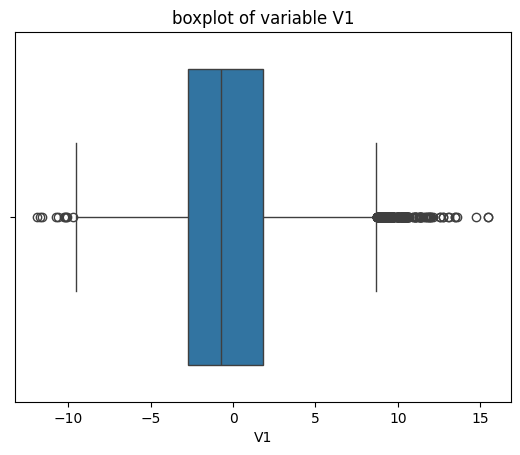

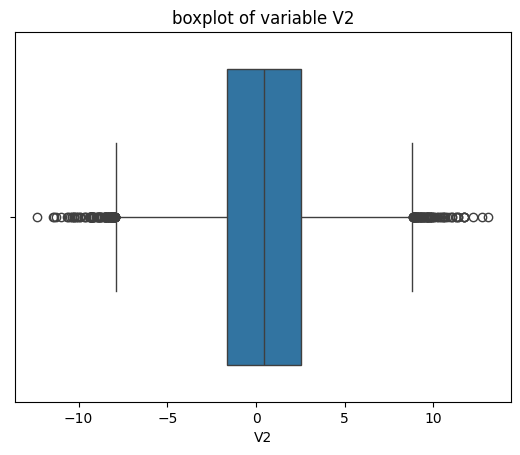

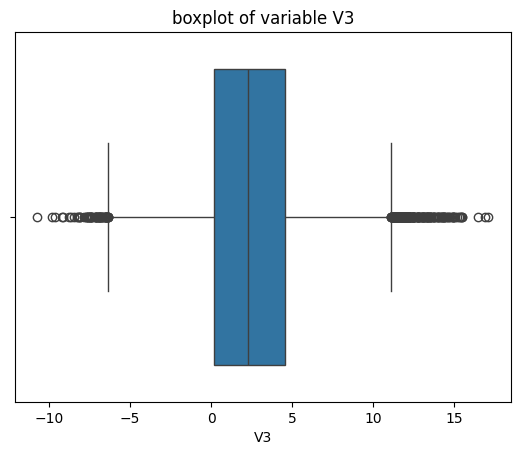

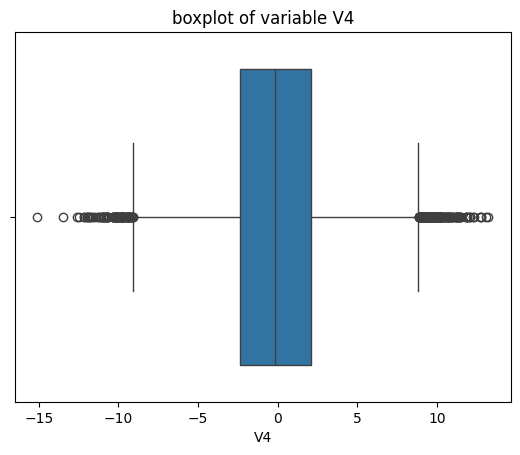

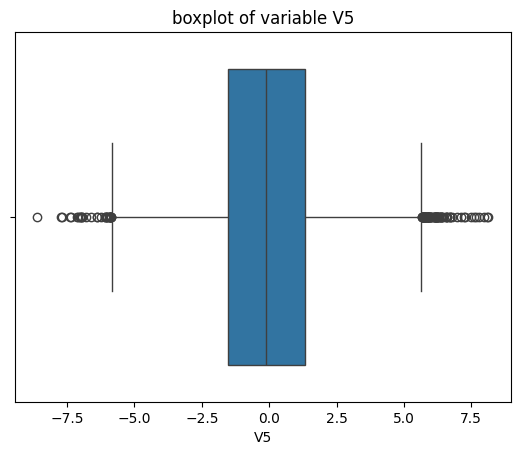

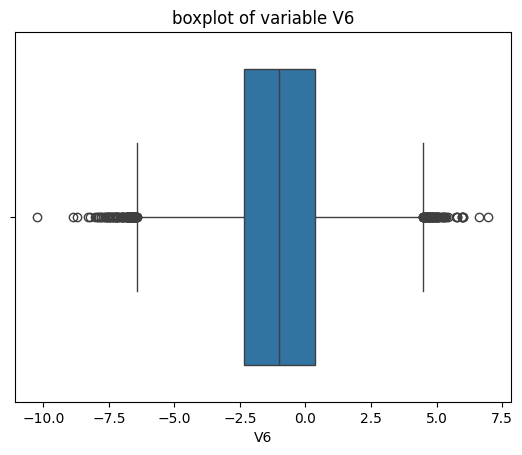

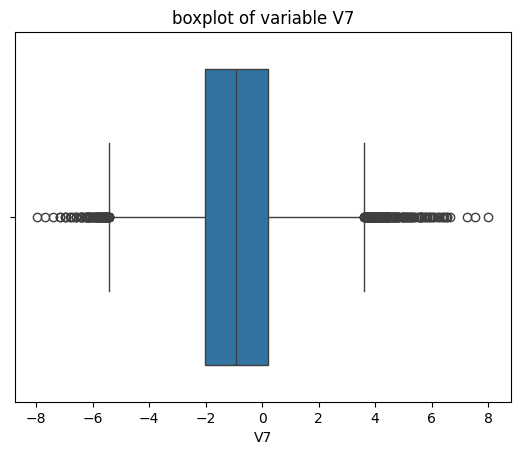

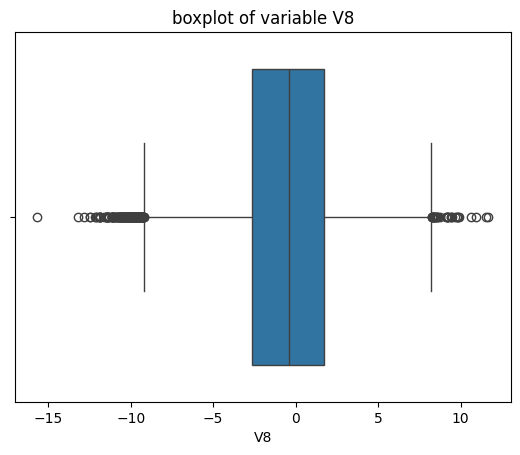

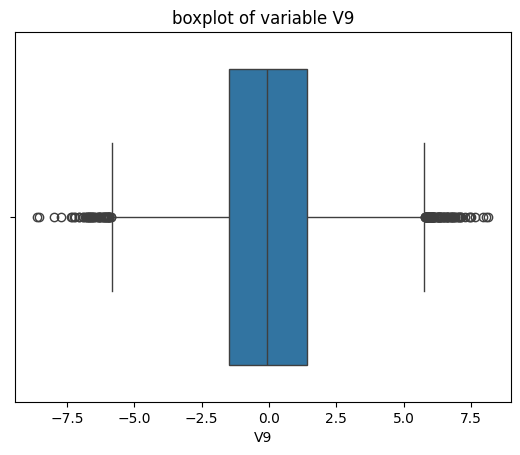

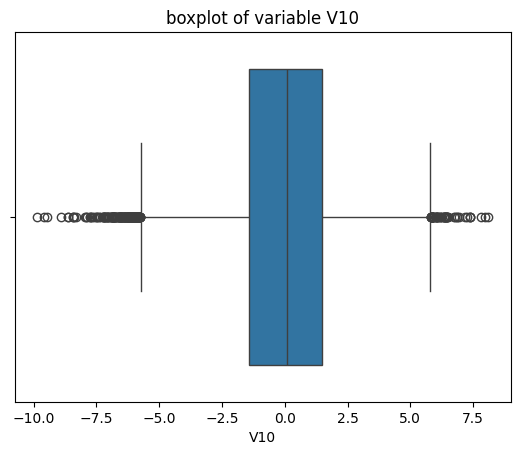

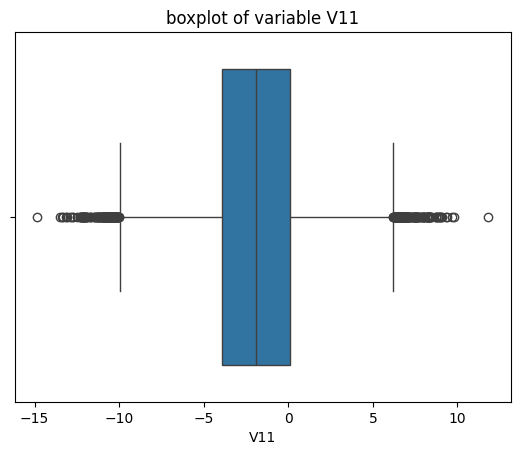

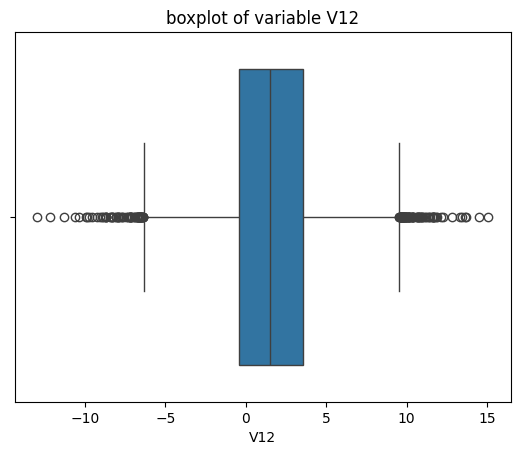

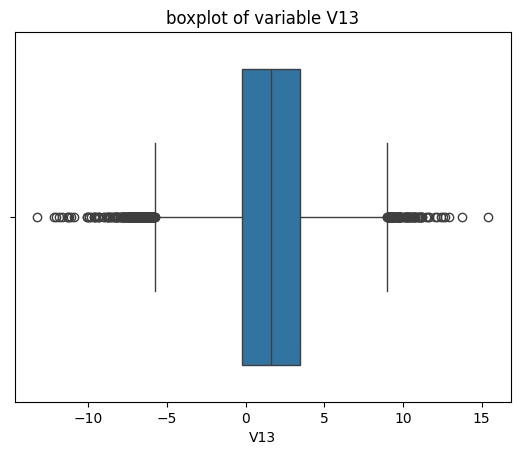

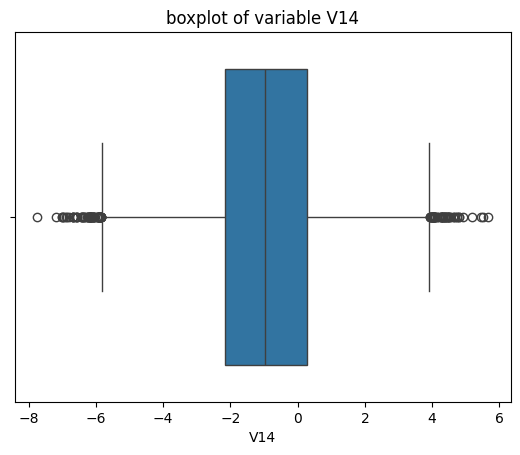

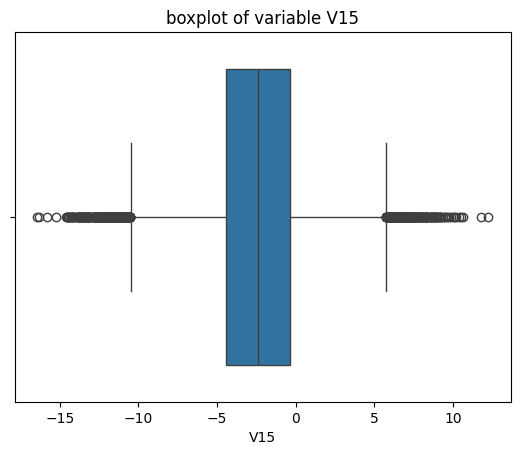

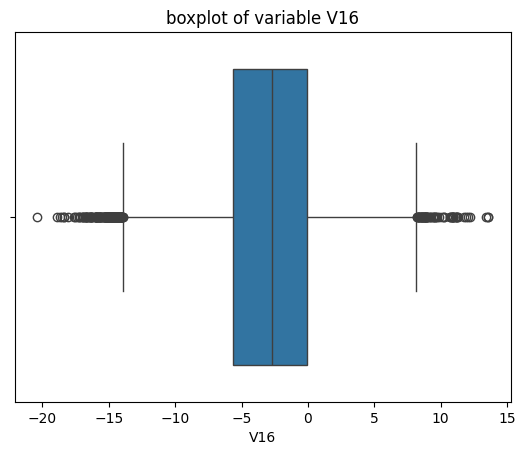

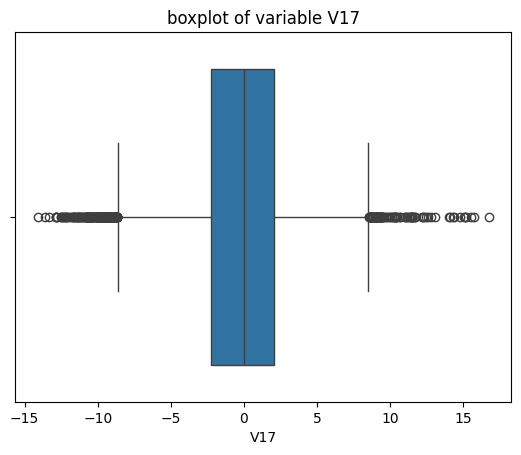

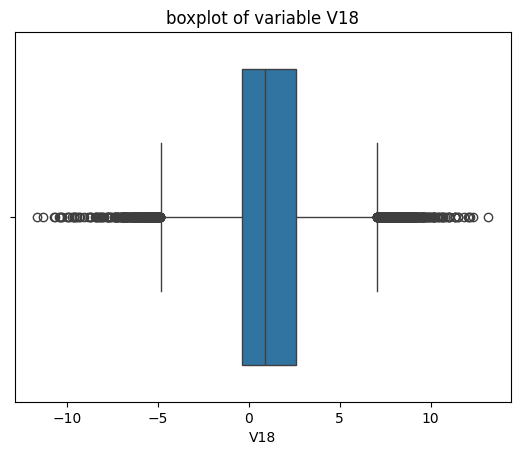

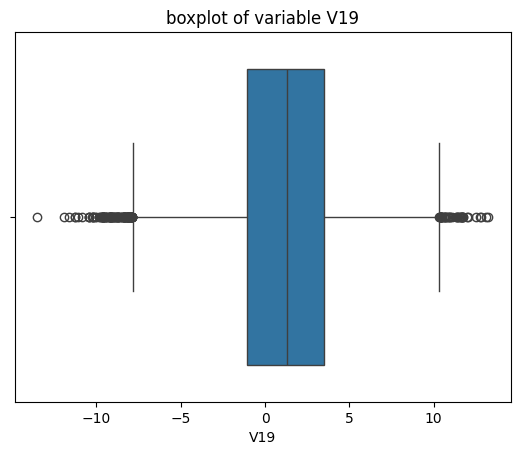

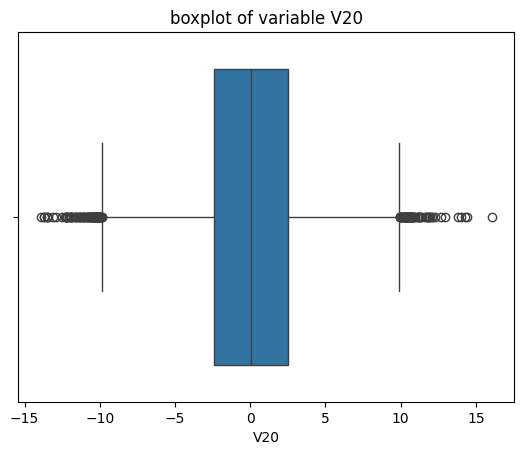

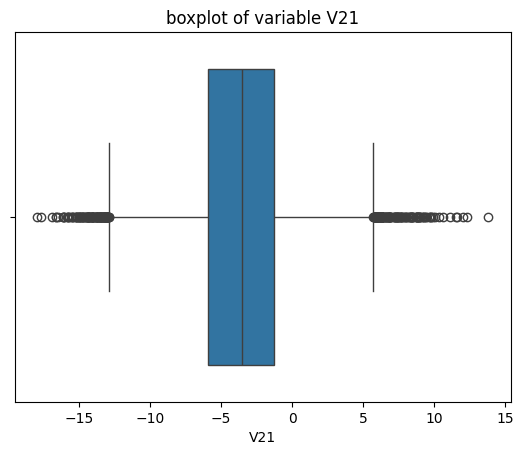

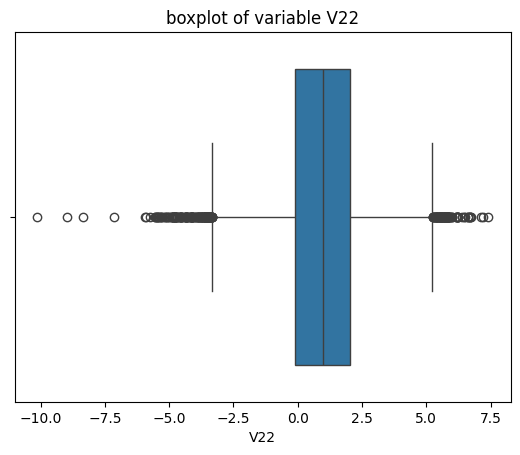

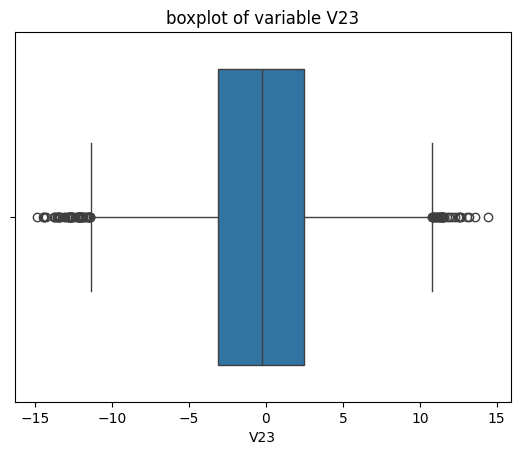

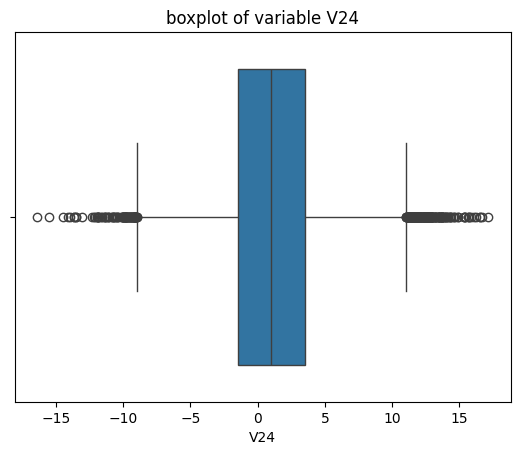

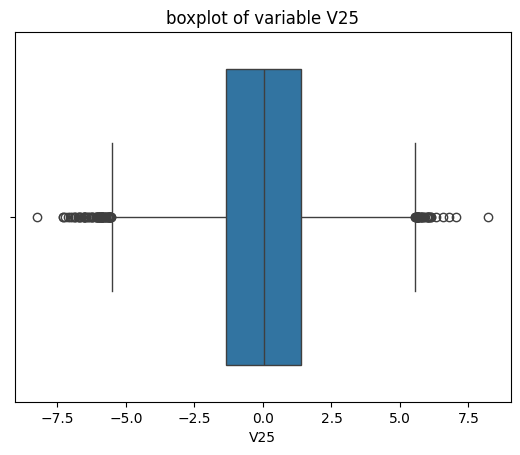

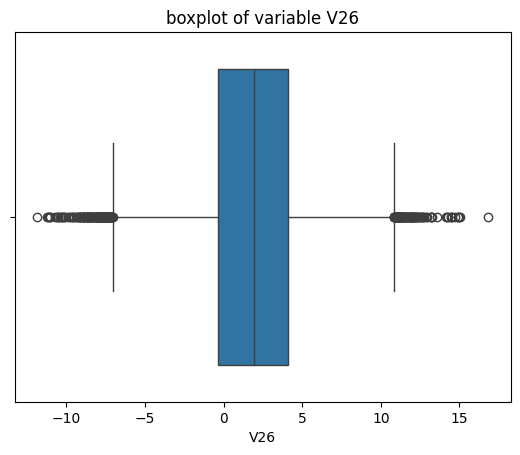

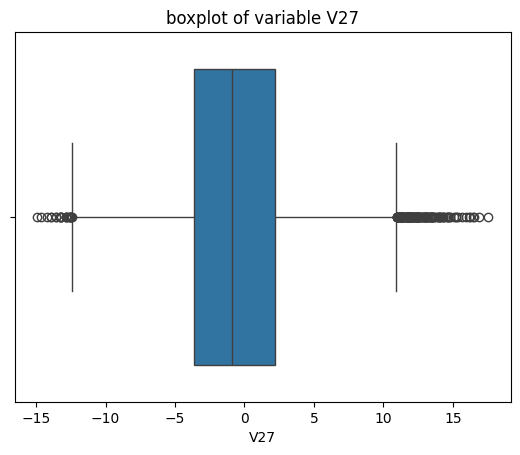

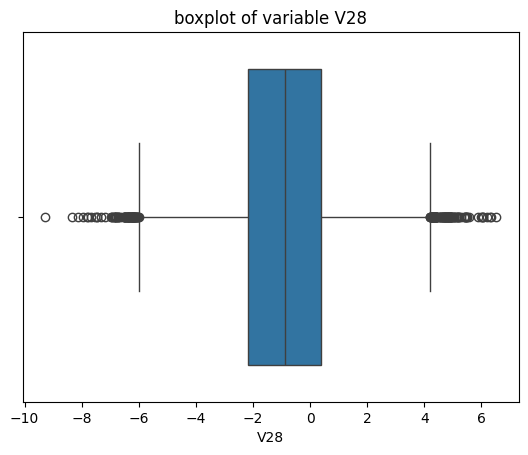

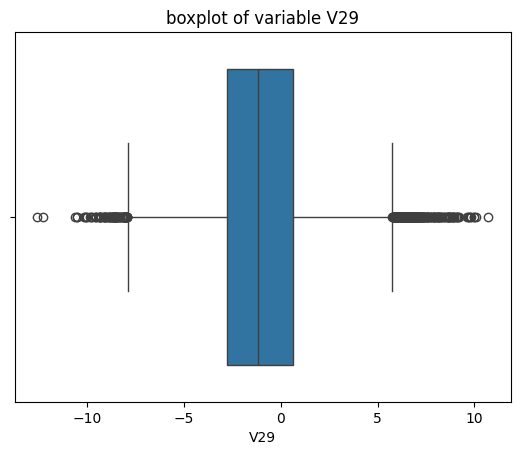

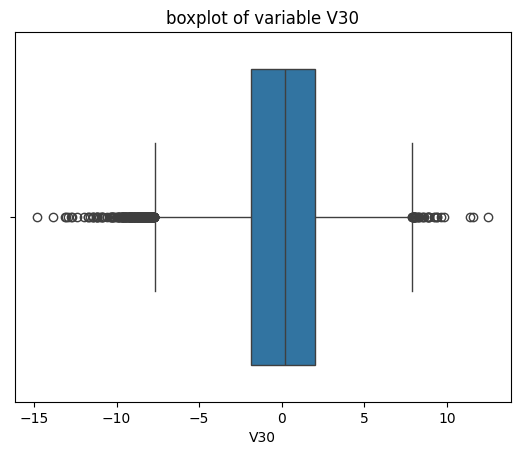

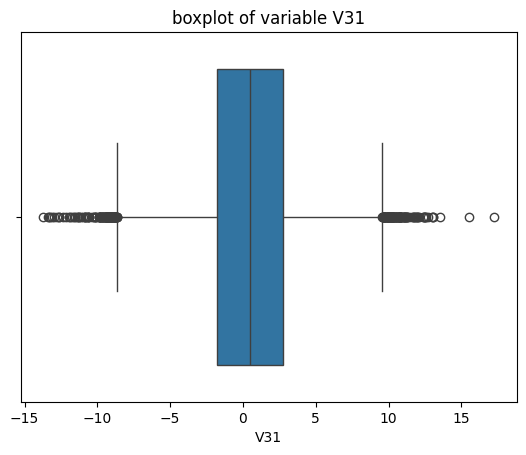

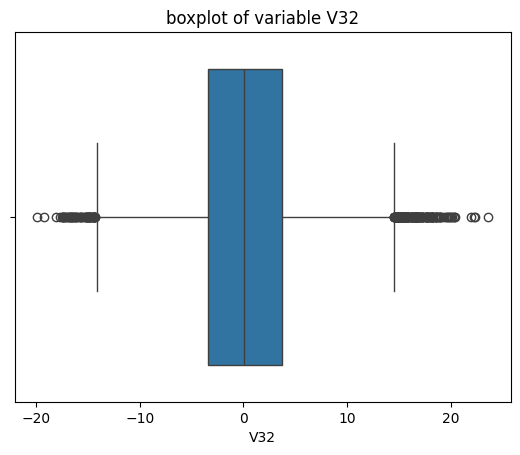

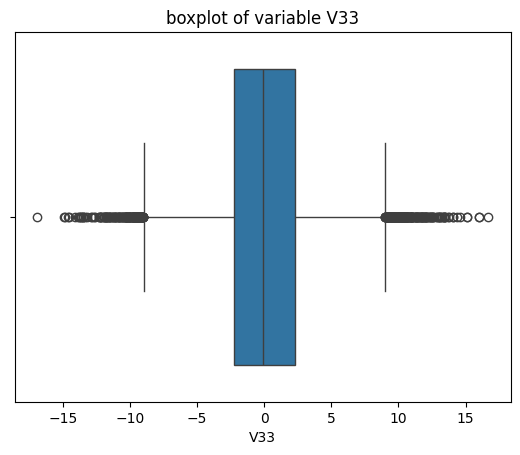

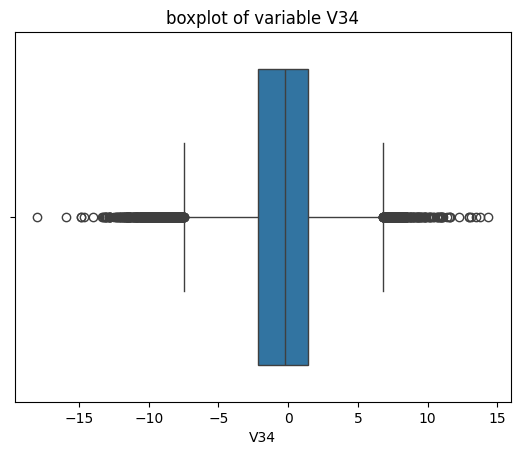

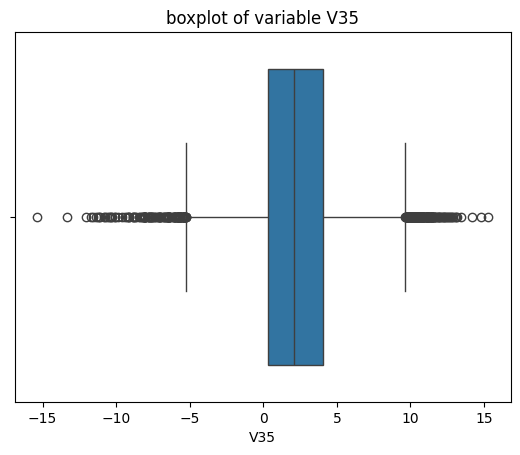

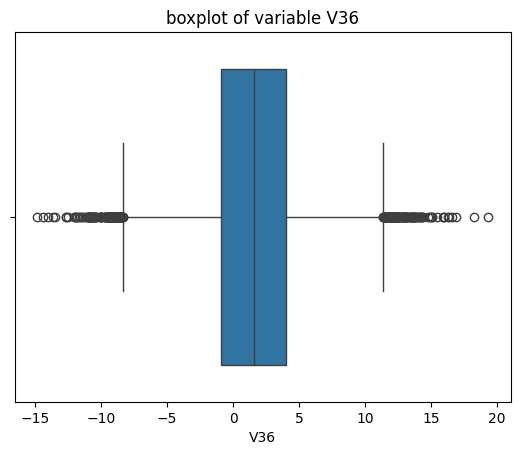

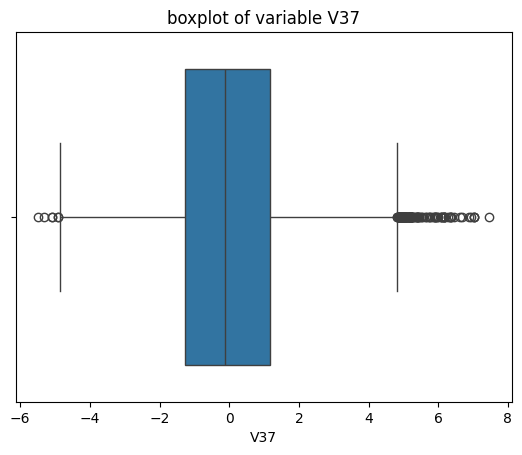

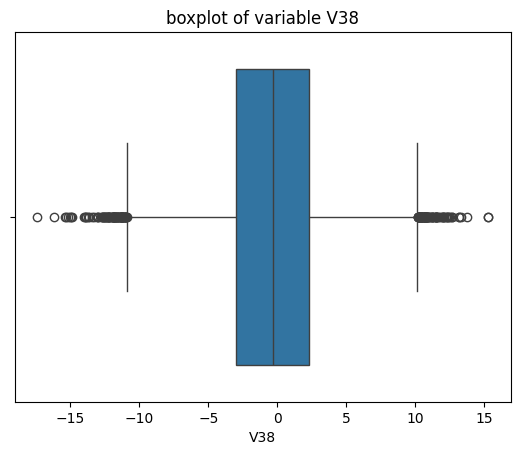

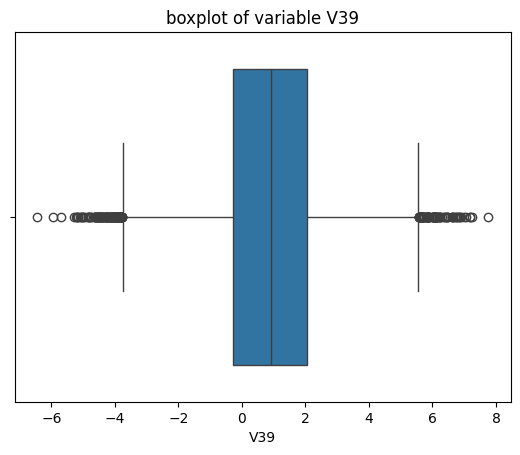

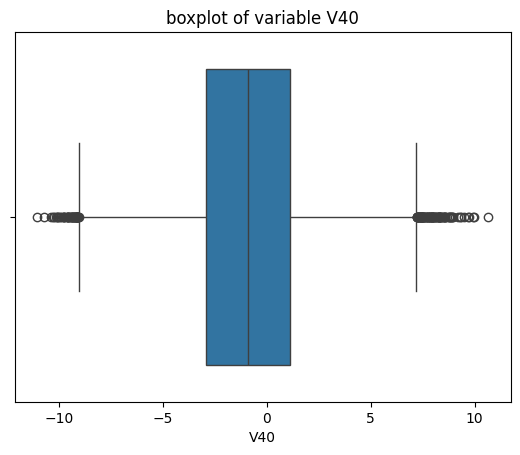

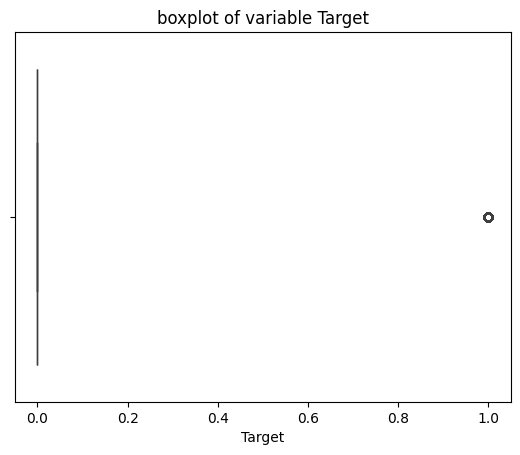

In [ ]:
# use sns to show a boxplot of the column 1
show_box_plot(train_data_set)

Observations

---
* Variables 7, 10, 13,18,22,25,36 have significant outliers compared to the rest of the dataset. However, these outliers are different in scale and direction.
For instance, some variables show extreme positive values exceeding 10, while others display negative outliers below -1.
* The boxplot shows that more of the data is between -5 and 5.



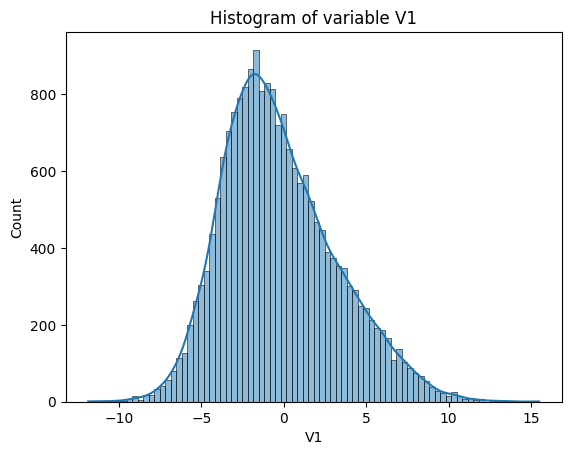

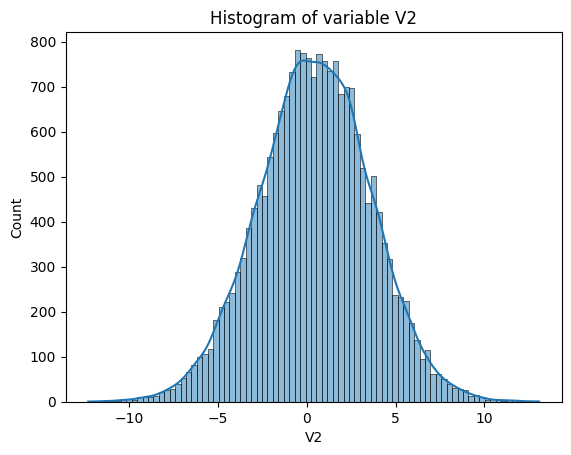

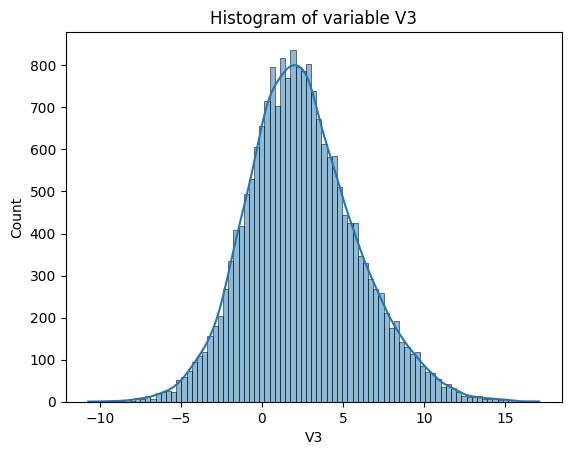

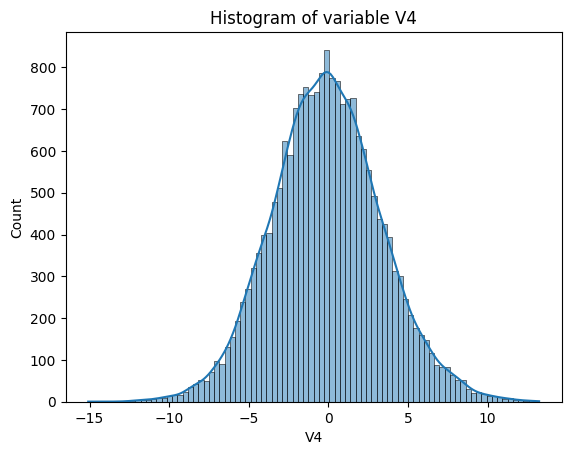

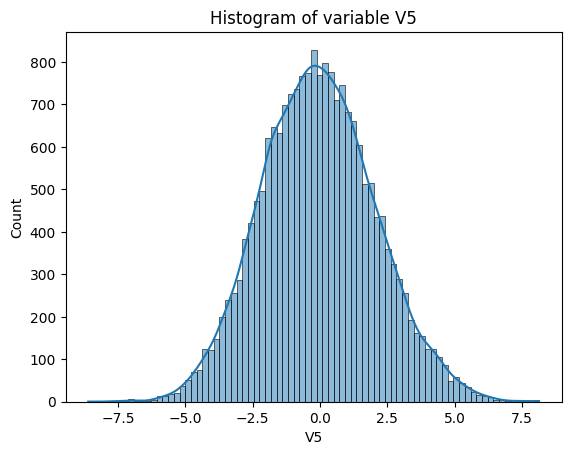

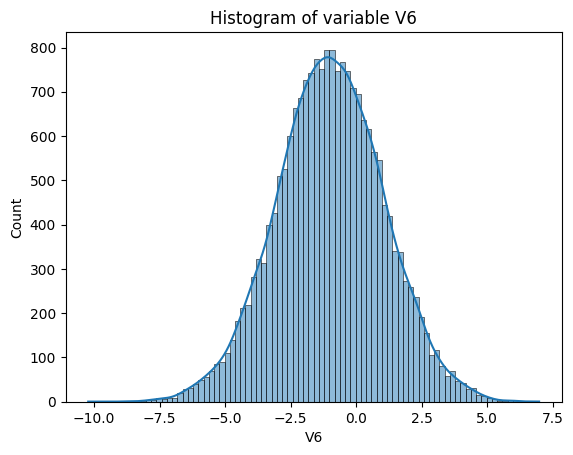

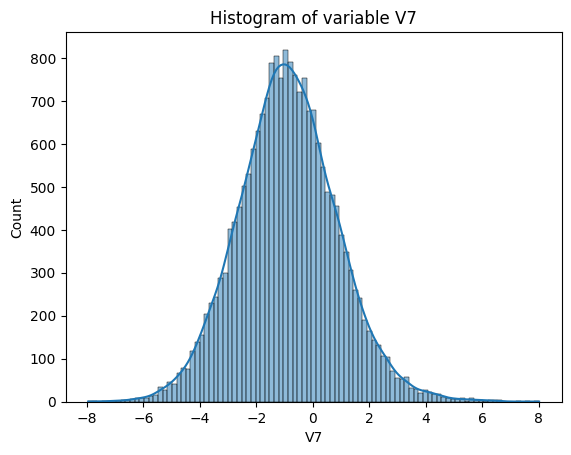

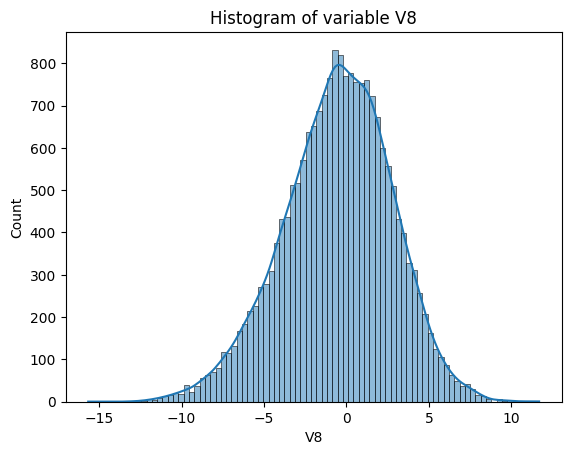

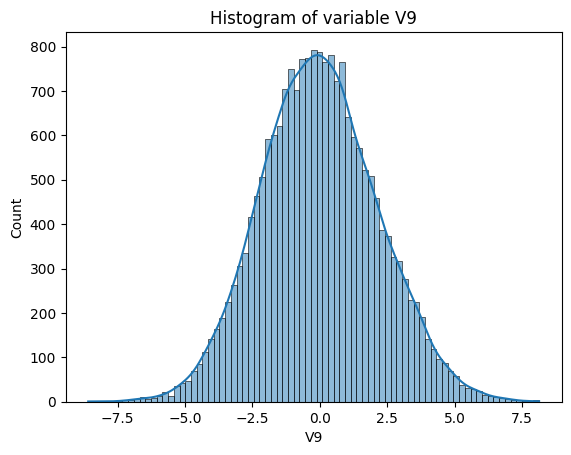

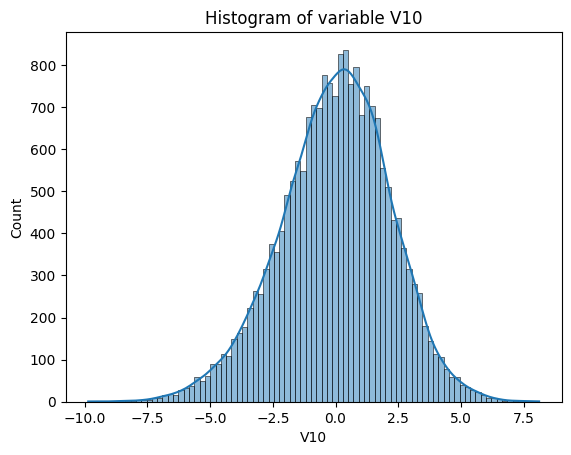

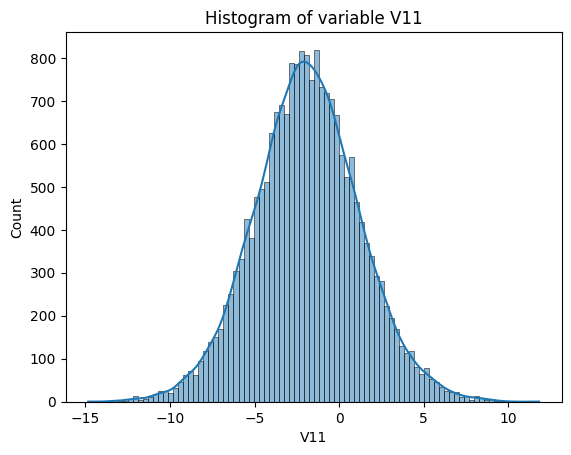

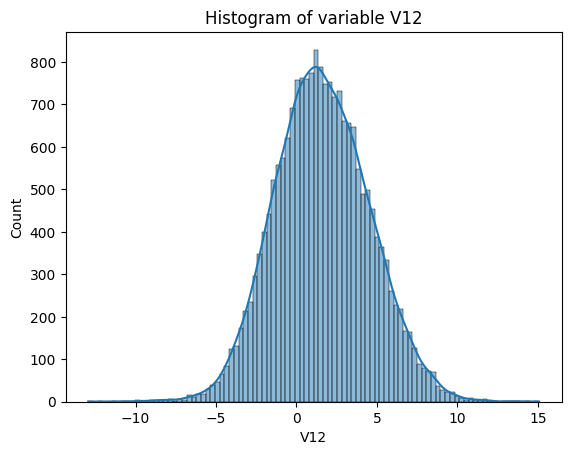

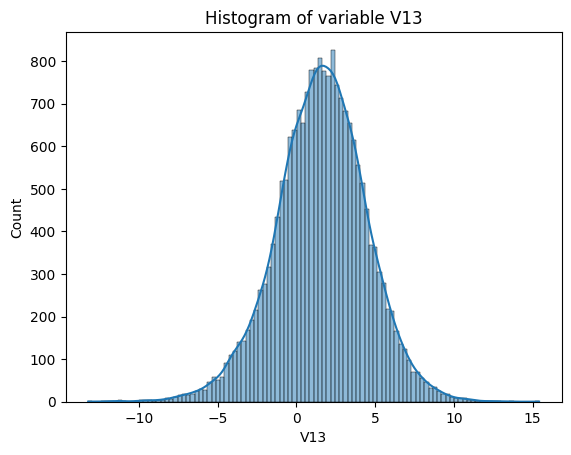

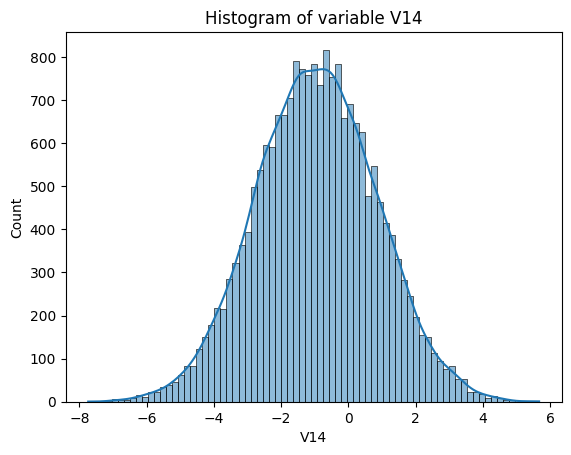

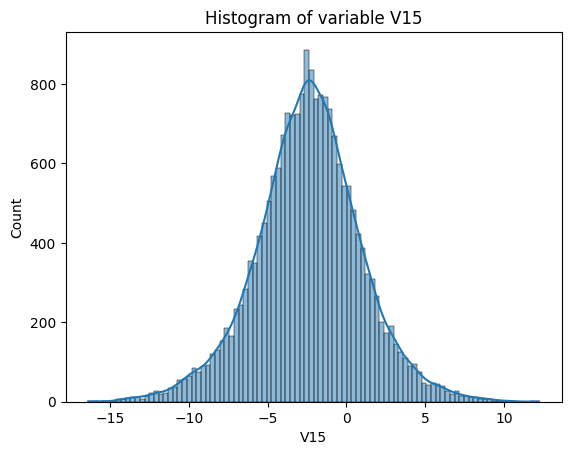

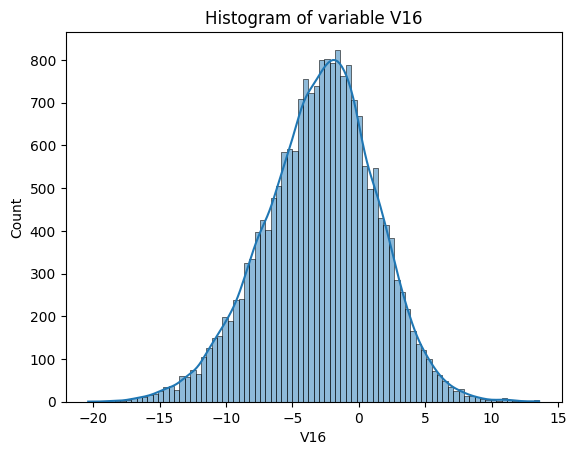

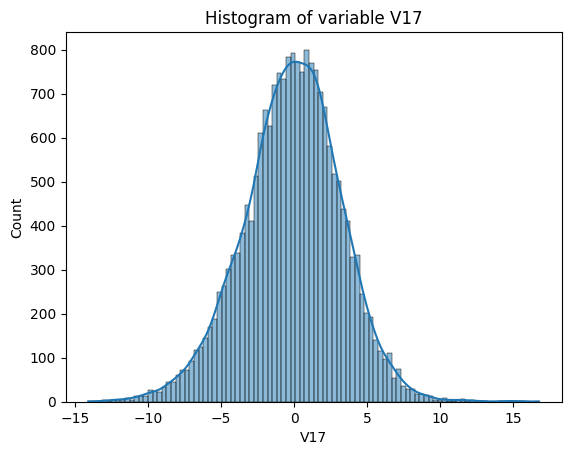

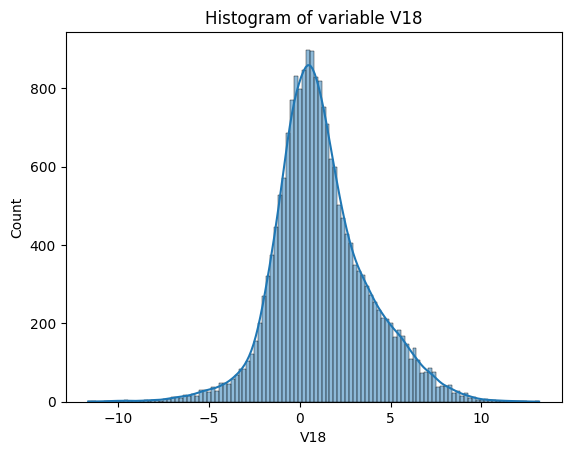

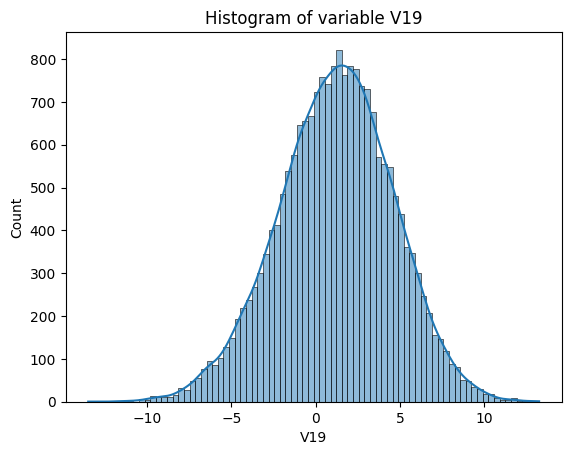

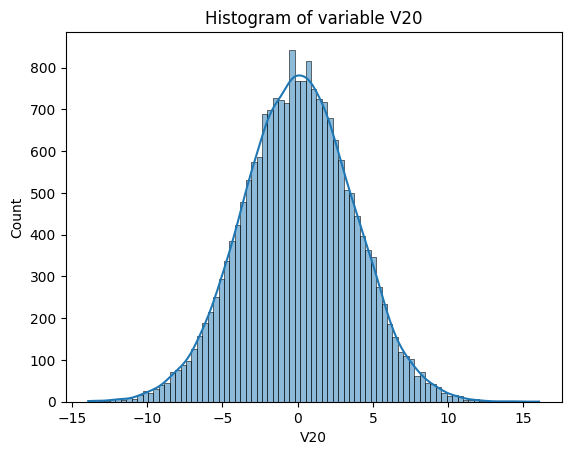

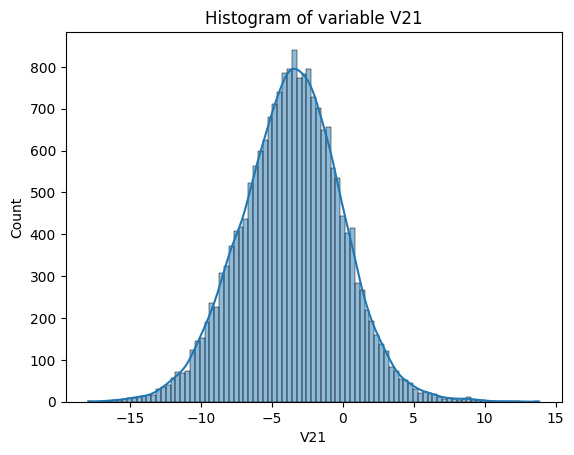

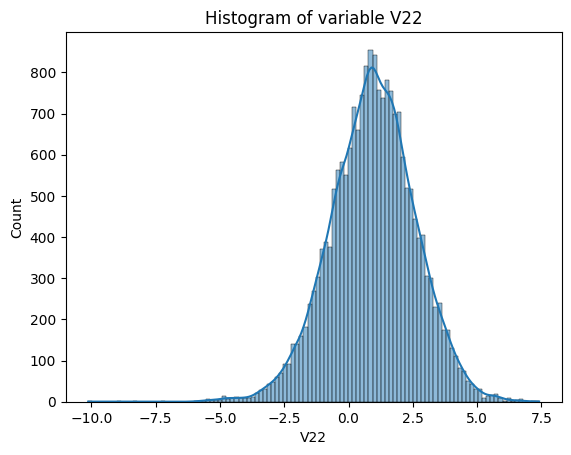

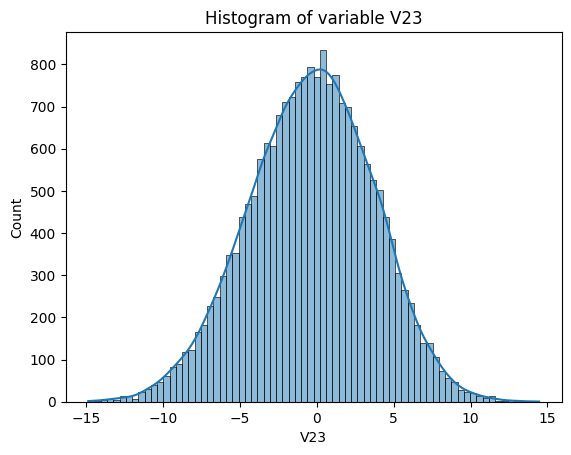

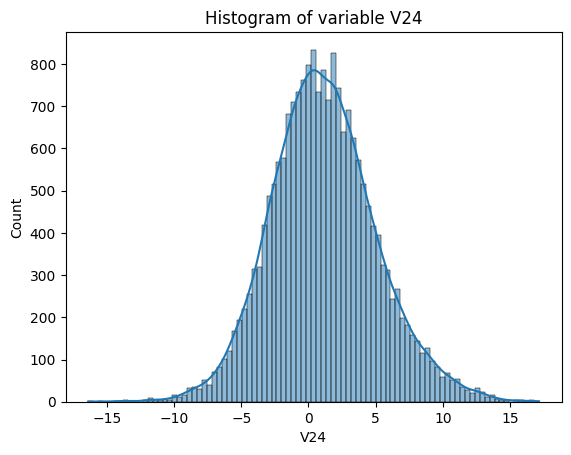

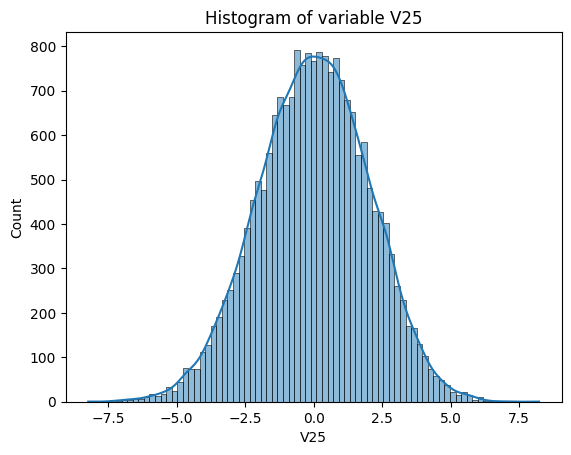

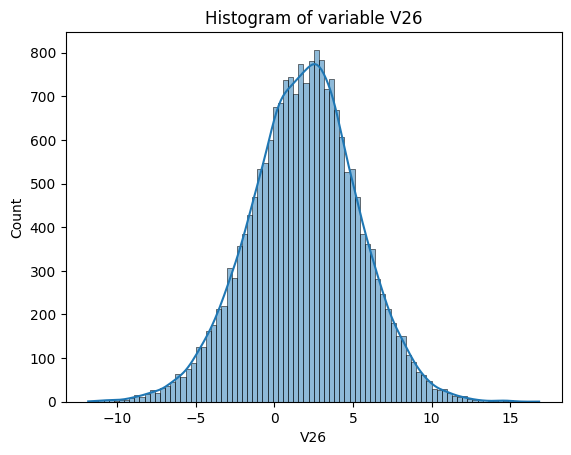

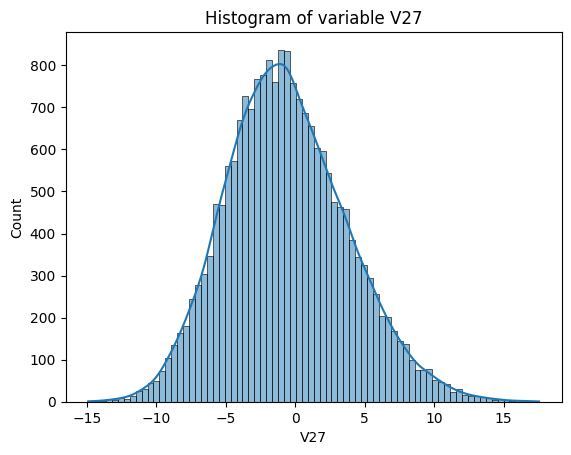

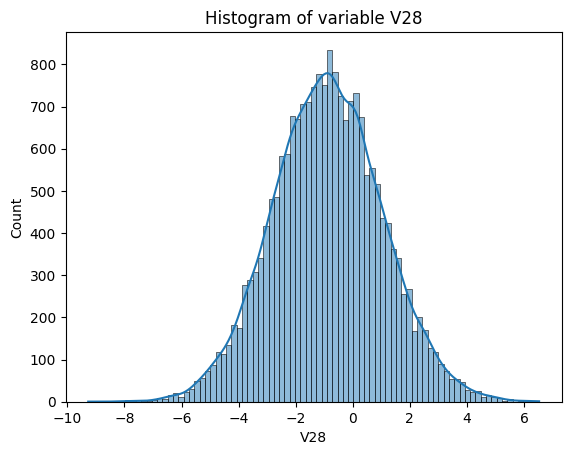

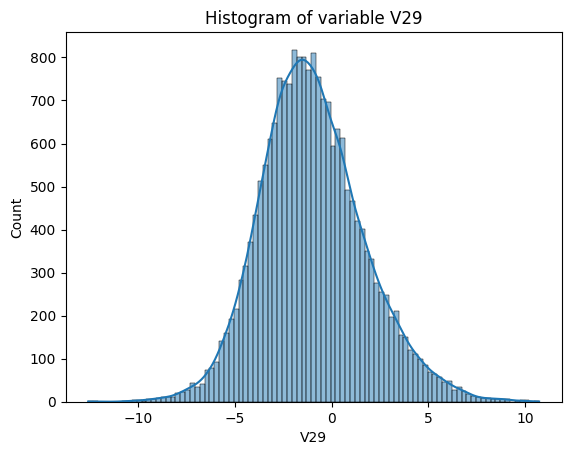

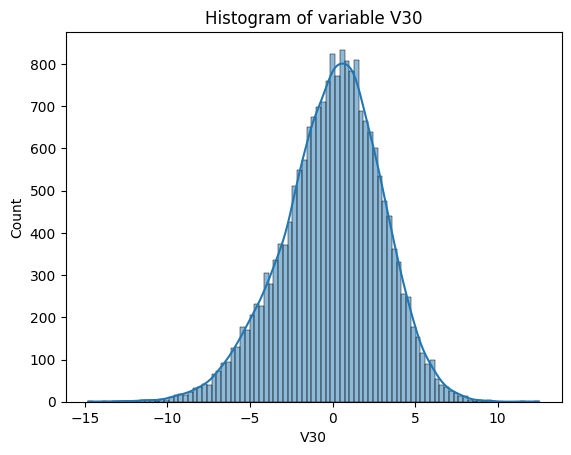

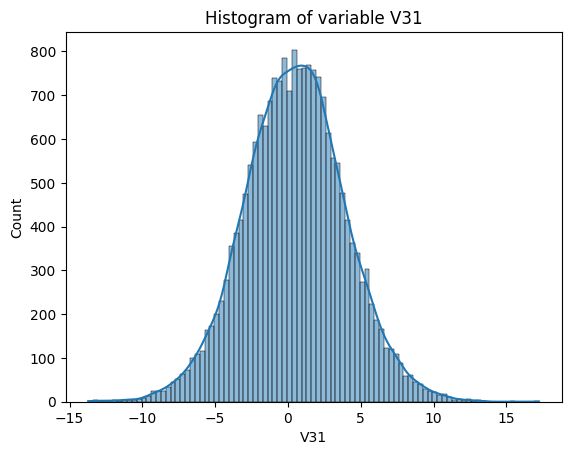

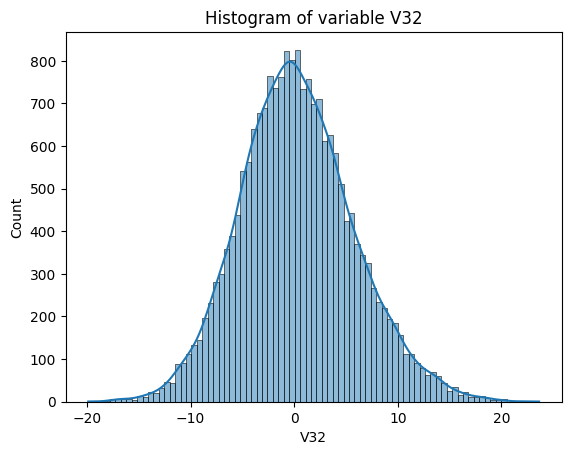

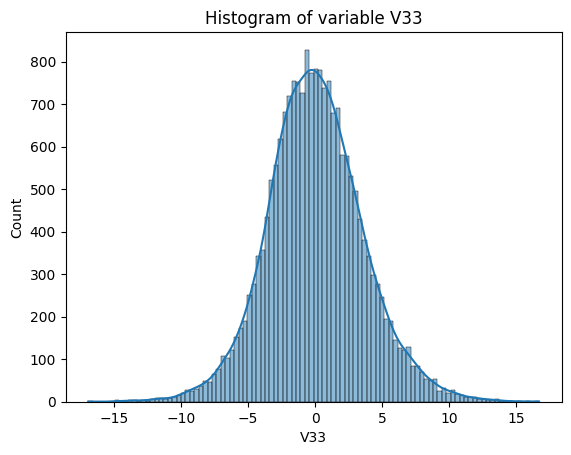

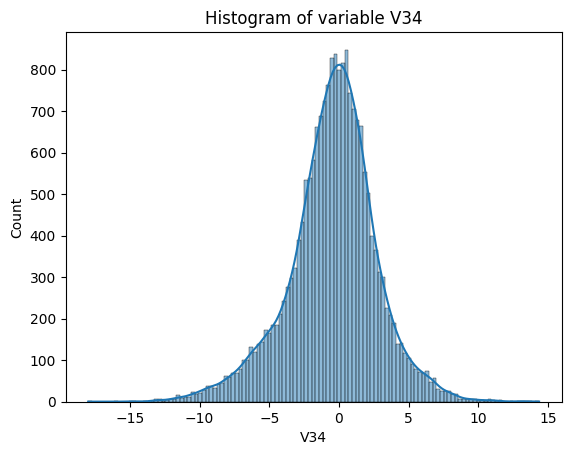

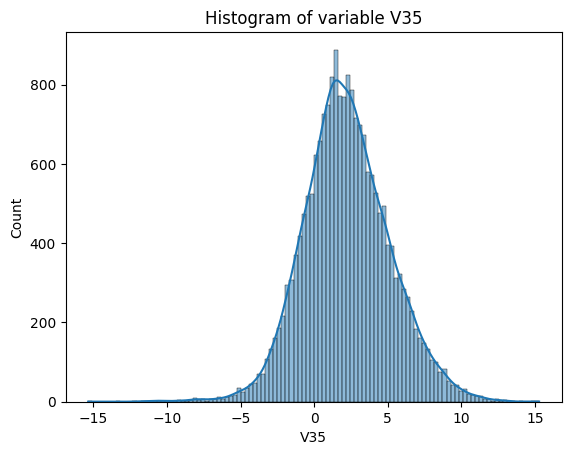

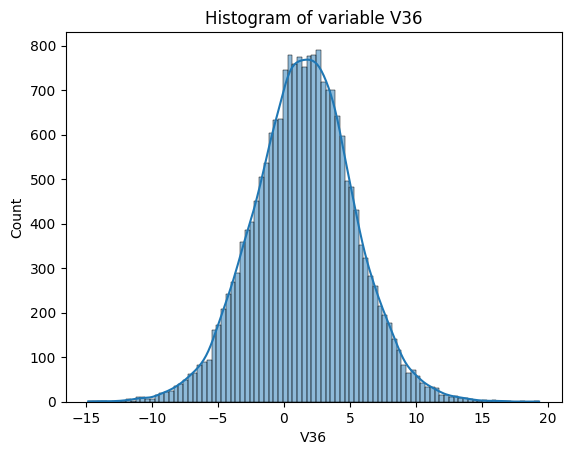

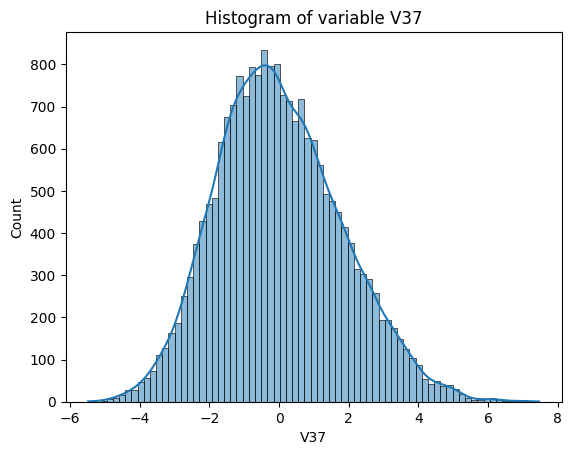

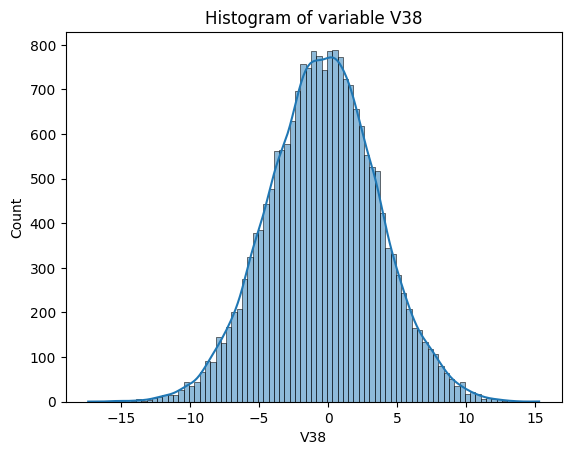

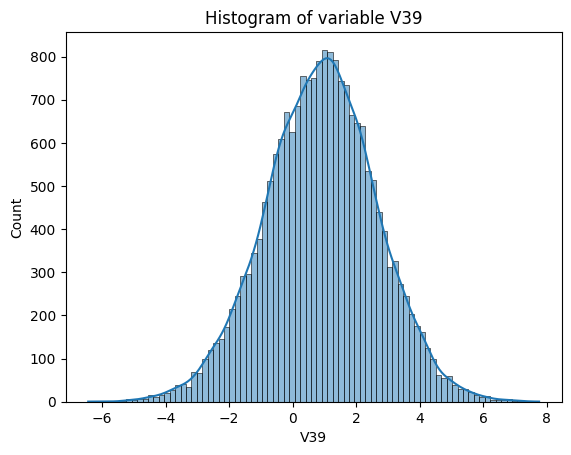

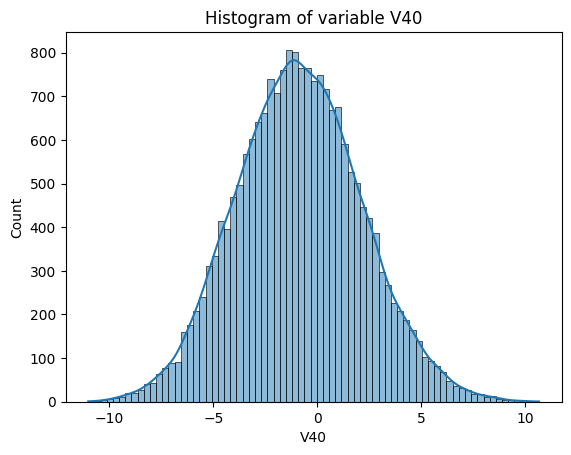

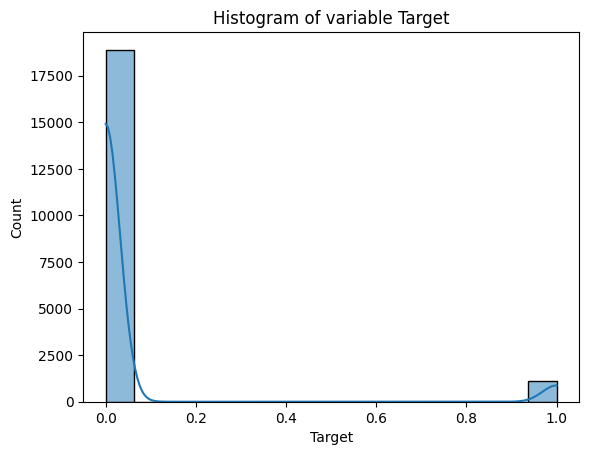

In [ ]:
# showing the hitplot of each
show_hist_plot(train_data_set)

Observations

---
* all the variables follow the nromal distribution.
* it looks like the target variable is imbalanced having a lot of data with no failure status (0).
* we will neet to use a special configuration when splitting the train data.


## Bivariate Analysis

In [ ]:
def show_box_and_line_plot_vs(dataset, column, target):
  sns.lineplot(
    data=train_data_set,
    x=target,
    y=column
    ).set(title=f"line plot of {column} vs {target}")
  plt.show(True)
  sns.boxplot(x=target, y=column, data=train_data_set).set(title=f"boxplot of {column} vs {target}")
  plt.show(True)

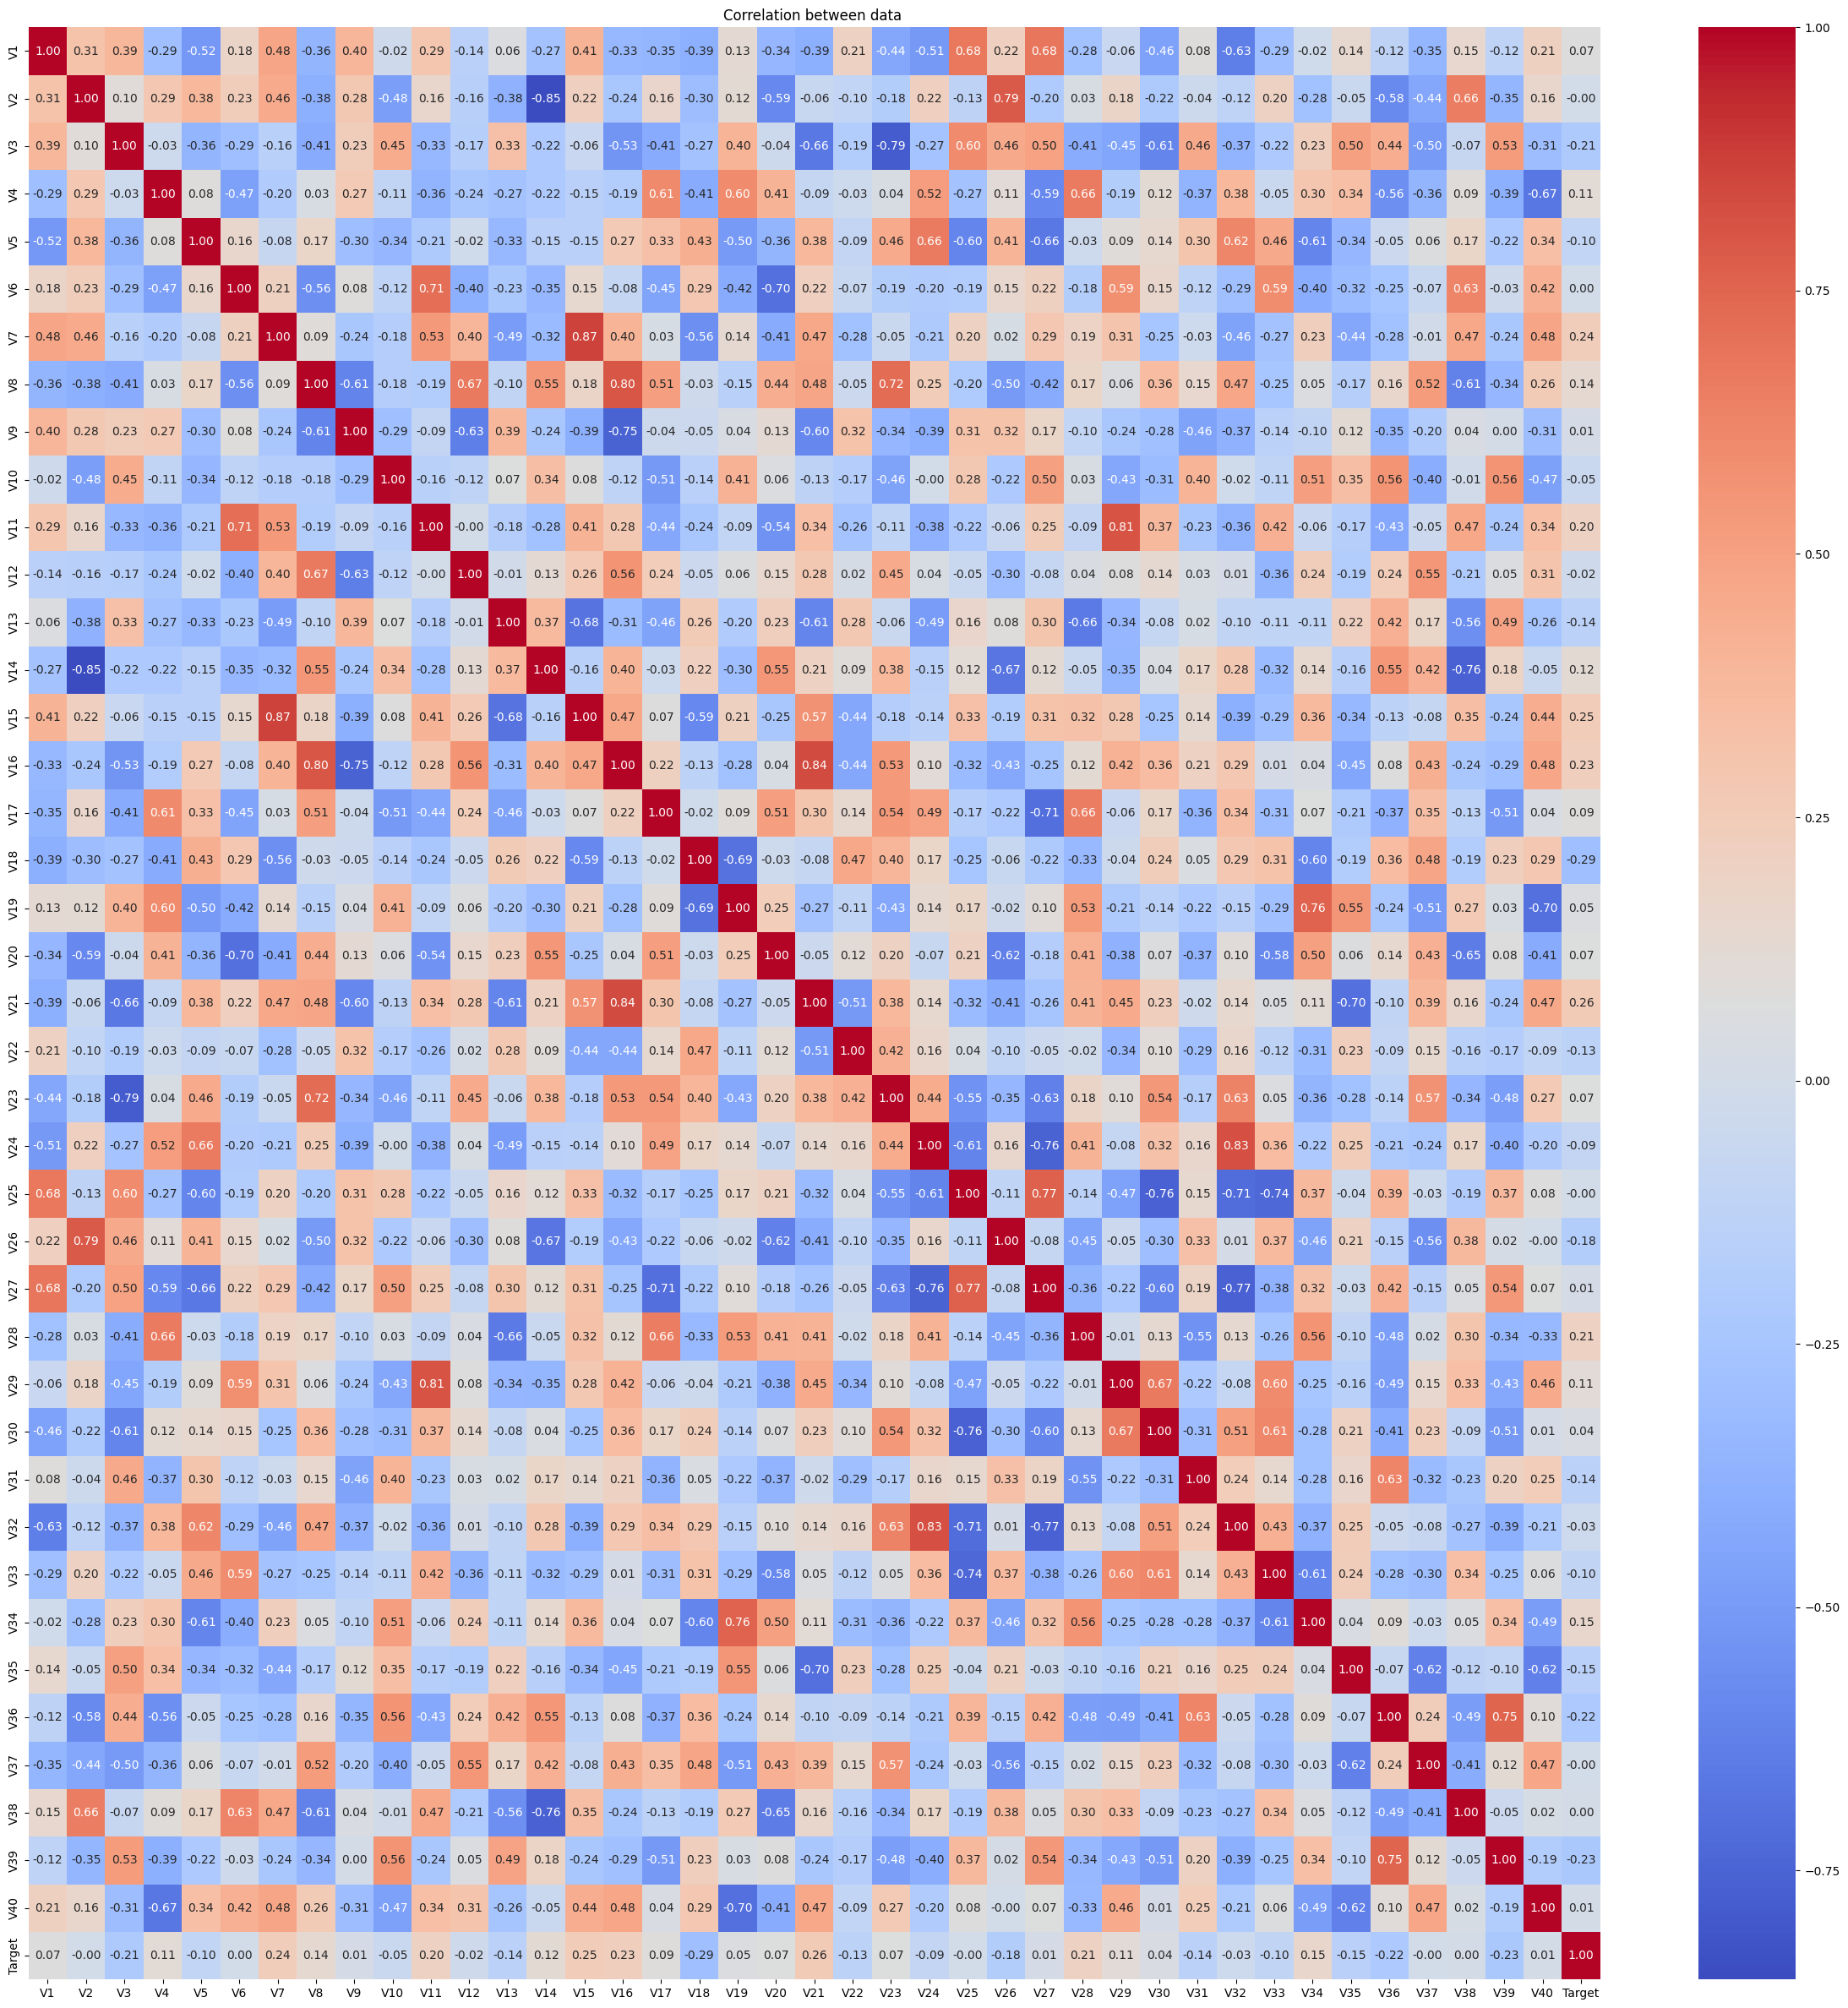

In [ ]:
cols = [ col for col in test_data_set.columns]

plt.figure(figsize=(30, 30))
sns.heatmap(
    train_data_set[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm"
).set(title='Correlation between data ')
plt.show()

Observations

---
* The V18 (−0.29) and V21 (0.26) have the strongest linear relationships with the Target variable.
* There is a the high correlation between V7 and V13 (0.87) and the strong inverse relationship between V2 and V14 (−0.85)



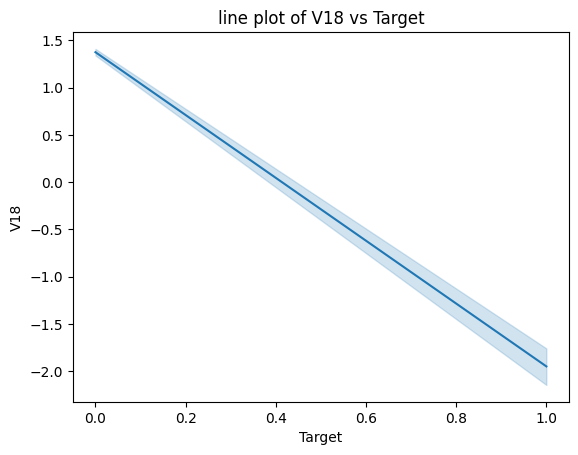

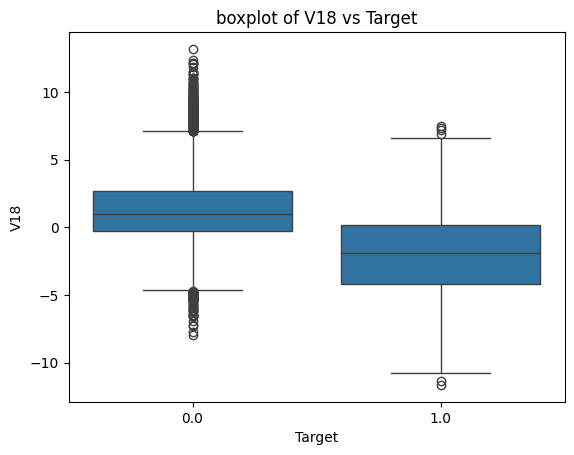

In [ ]:
show_box_and_line_plot_vs(train_data_set, 'V18', 'Target')

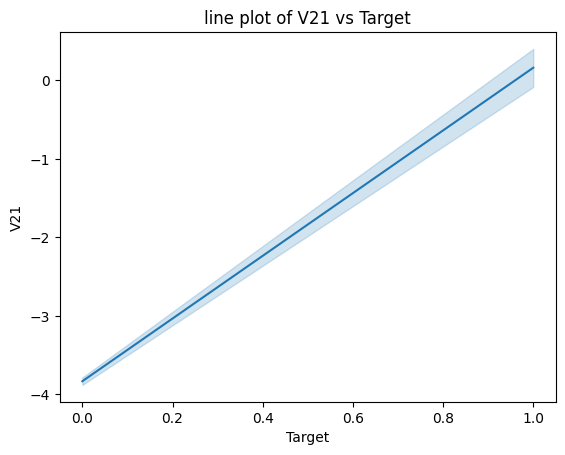

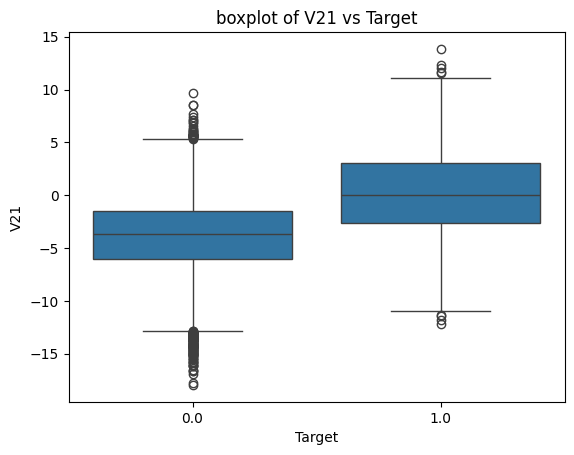

In [ ]:
show_box_and_line_plot_vs(train_data_set, 'V21', 'Target')

Observations:

---
* The values of V18 vs the target and V21 vs Target seems to be different depedning of the status.
* the Failure status is Failure (1) the V18 usually has negative values
* The values of 21 seem to be higer when status is failure (1) moving to the positive site


# **Data Preprocessing**

In [ ]:
# dive the test data to have the train, test and validation
X = train_data_set.drop('Target', axis=1)
y = train_data_set['Target']

# we have unbalanced data so we need stratify y
X_train, X_val, y_train, y_val = train_test_split( X, y, test_size=0.2, random_state=5, stratify=y)

X_test = test_data_set.drop('Target', axis=1)
y_test = test_data_set['Target']


In [ ]:
# we need to use the Simple Imputer with the median to fit the nulls of V1 and V2 variables in train set and then transform the test set with the result
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test = imputer.transform(X_test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# **Model Building**

Utility Methods

---




In [ ]:
def get_class_wiegths(y_train):
  # Calculate weights based on your training labels
  weights = class_weight.compute_class_weight(
      class_weight='balanced',
      classes=np.unique(y_train),
      y=y_train
  )

  # Convert to the dictionary
  dict_weights = {0: weights[0], 1: weights[1]}
  return dict_weights

In [ ]:
def evaluate_tree(y, prediction):
  # scoring the tree.
  recall =     recall_score(y, prediction)
  acc =        accuracy_score(y, prediction)
  precision =  precision_score(y, prediction)
  f1 =         f1_score(y, prediction)

  # printing the results.
  print("-"*50)
  print(f'Accuracy:  {acc * 100:.2f}%')
  print(f'Recall: {recall * 100:.2f}%')
  print(f'Precision: {precision * 100:.2f}%')
  print(f'F1: {f1 * 100:.2f}%')

  confusion_matrix_prediction_train = confusion_matrix(y, prediction)
  #show hitmap of the confustion matrix
  print("-"*50)
  print('Confusion Matrix:')
  print(confusion_matrix_prediction_train)
  return f1, recall

In [ ]:
def run_model_in_validation_and_test(model_name, model, x_train_p, y_train_p, is_test=False):
  print(f"Model: {model_name}")
  print("*"*50)
  print('TEST')
  # executes the model in the train set
  predicted_model_probs = model.predict(x_train_p)
  predicted_model = (predicted_model_probs > 0.5).astype(int) # Convert probabilities to binary predictions
  score_train, recall_train = evaluate_tree(y_train_p, predicted_model)
  if not is_test:
    print("-"*50)
    print('VALIDATION')
    # executes the model in the validation set
    validation_predicted_model_probs = model.predict( X_val )
    validation_predicted_model = (validation_predicted_model_probs > 0.5).astype(int) # Convert probabilities to binary predictions
    score_validation, recall_validation = evaluate_tree( y_val, validation_predicted_model)

    # calculates the accurency and f1 scores diff between sets
    diff_score = score_train - score_validation
    recall = recall_train - recall_validation
    print("-"*50)
    return {
              "name": model_name,
              "recall": recall_validation,
              "f1_score": diff_score,
              "recall_score": recall,
            }

## Model Evaluation Criterion

To align with the financial objectives of ReneWind, can translate the possible predictions into a cost hierarchy:

* High Cost - False Negatives (FN): Undetected failures requiring full generator replacement.

* Medium Cost - True Positives (TP): Correctly identified failures allowing for repair.

* Low Cost - False Positives (FP): inspections where no failure exists.


**Primary Metric: Recall**

Our primary objective is to minimize False Negatives, as the cost of replacement higher than inspection or repair. Tha is why, Recall is our most important metric.

also we will need to add a class wieght parameter because the data is imbalance, and we need to prevent FN.

**Secondary Metric: F1-Score & Stability**

To ensure the model is practical and does not trigger excessive false alarms, we combine Recall with the F1-score. We use custom utility methods to calculate the difference between training/validation scores and test data.

**The final decission :**

The model with the highest Validation Recall and A low Generalization Gap in both F1 and Recall (to ensure the model is stable and not overfitting) Will be the best model.

Because prioritizing stable high-recall models, we maximize the reduction in overall maintenance costs for the company.


## Initial Model Building (Model 0)

- Let's start with a neural network consisting of
  - just one hidden layer
  - activation function of ReLU
  - SGD as the optimizer

In [ ]:
# adding SGD optimizer to the model
# configuration varables
OPTIMIZER = tensorflow.keras.optimizers.SGD()
LOSS_FUNCTION = 'binary_crossentropy'
METRICS = ['Recall']

In [ ]:
# select the epochs and the batch size
EPOCHS = 100
BATCH_SIZE = 32
SEED = 812

In [ ]:
# freeing up memory
tf.keras.utils.set_random_seed(SEED)
tf.keras.backend.clear_session()

In [ ]:
X_train.shape

(16000, 40)

In [ ]:
# creating the model and addint layers
model_0 = Sequential()
# configuring the shape of the  model
model_0.add(Input(shape=(X_train.shape[1],)))

# adding the layers
model_0.add(Dense(14, activation="relu"))
model_0.add(Dense(1, activation="sigmoid"))

In [ ]:
# check the structure of our model
model_0.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 589 (2.30 KB)

 Trainable params: 589 (2.30 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# compiling the model with th e configuration
model_0.compile(loss=LOSS_FUNCTION, optimizer=OPTIMIZER, metrics = METRICS)

In [ ]:
# Executing the model and saving the excution time
start_time = time.time()

# training the model with SGD and 2 layers
history  = model_0.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size=BATCH_SIZE, epochs=EPOCHS)

end_time = time.time()
execution_time = end_time - start_time

print(f"the executin time is {execution_time}")

Epoch 1/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - Recall: 0.1542 - loss: 0.4091 - val_Recall: 0.2117 - val_loss: 0.1749
Epoch 2/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.2562 - loss: 0.1556 - val_Recall: 0.4189 - val_loss: 0.1389
Epoch 3/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.4051 - loss: 0.1263 - val_Recall: 0.4775 - val_loss: 0.1239
Epoch 4/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.4698 - loss: 0.1126 - val_Recall: 0.5135 - val_loss: 0.1152
Epoch 5/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.5167 - loss: 0.1042 - val_Recall: 0.5225 - val_loss: 0.1094
Epoch 6/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.5520 - loss: 0.0980 - val_Recall: 0.5495 - val_loss: 0.1049
Epoch 7/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.5692 - loss: 0.0930 - val_Recall: 0.5676 - val_loss: 0.1010
Epoch 8/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Recall: 0.5876 - loss: 0.0889 - val_Recall: 0.5991 - val_loss: 0.0976


In [ ]:
# using the trained netwrok to predict in validation and test then showing the metrics
run_model_in_validation_and_test("model_0", model_0, X_train, y_train, False)

Model: model_0
**************************************************
TEST
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
--------------------------------------------------
Accuracy:  99.01%
Recall: 83.78%
Precision: 98.02%
F1: 90.35%
--------------------------------------------------
Confusion Matrix:
[[15097    15]
 [  144   744]]
--------------------------------------------------
VALIDATION
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
--------------------------------------------------
Accuracy:  98.75%
Recall: 80.63%
Precision: 96.24%
F1: 87.75%
--------------------------------------------------
Confusion Matrix:
[[3771    7]
 [  43  179]]
--------------------------------------------------


{'name': 'model_0',
 'recall': 0.8063063063063063,
 'f1_score': 0.026009857494910582,
 'recall_score': 0.03153153153153154}

Observations:

---
This model presents good accurency but our main concern is the recall that has a loss of 22%, and a f-score of 2%.

# **Model Performance Improvement**

## Model 1 ( adding Weights )

In [ ]:
# freeing up memory
tf.keras.utils.set_random_seed(SEED)
tf.keras.backend.clear_session()

In [ ]:
OPTIMIZER = tensorflow.keras.optimizers.SGD()
LOSS_FUNCTION = 'binary_crossentropy'
METRICS = ['Recall']
WEIGHTS = get_class_wiegths(y_train)

In [ ]:
# creating the model and addint layers
model_sgd_with_weights = Sequential()
# configuring the shape of the  model
model_sgd_with_weights.add(Input(shape=(X_train.shape[1],)))

# adding the layers
model_sgd_with_weights.add(Dense(14, activation="relu"))
model_sgd_with_weights.add(Dense(1, activation="sigmoid"))

In [ ]:
# check the structure of our model
model_sgd_with_weights.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 589 (2.30 KB)

 Trainable params: 589 (2.30 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# compiling the model with th e configuration
model_sgd_with_weights.compile(loss=LOSS_FUNCTION, optimizer=OPTIMIZER, metrics = METRICS)


In [ ]:
# Executing the model and saving the excution time
start_time = time.time()

# training the model
history  = model_sgd_with_weights.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size=BATCH_SIZE, epochs=EPOCHS, class_weight=WEIGHTS)

end_time = time.time()
execution_time = end_time - start_time

print(f"the executin time is {execution_time}")

Epoch 1/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - Recall: 0.8261 - loss: 0.5344 - val_Recall: 0.8829 - val_loss: 0.4025
Epoch 2/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8903 - loss: 0.3248 - val_Recall: 0.8829 - val_loss: 0.3198
Epoch 3/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8909 - loss: 0.2900 - val_Recall: 0.8739 - val_loss: 0.2854
Epoch 4/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8935 - loss: 0.2725 - val_Recall: 0.8784 - val_loss: 0.2637
Epoch 5/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8942 - loss: 0.2605 - val_Recall: 0.8784 - val_loss: 0.2489
Epoch 6/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8950 - loss: 0.2505 - val_Recall: 0.8739 - val_loss: 0.2386
Epoch 7/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8968 - loss: 0.2428 - val_Recall: 0.8784 - val_loss: 0.2302
Epoch 8/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8981 - loss: 0.2361 - val_Recall: 0.8784 - val_loss: 0.2232


In [ ]:
# using the trained netwrok to predict in validation and test then showing the metrics
run_model_in_validation_and_test("model with SGD weights", model_sgd_with_weights, X_train, y_train, False)

Model: model with SGD weights
**************************************************
TEST
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
--------------------------------------------------
Accuracy:  97.16%
Recall: 92.00%
Precision: 68.08%
F1: 78.26%
--------------------------------------------------
Confusion Matrix:
[[14729   383]
 [   71   817]]
--------------------------------------------------
VALIDATION
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
--------------------------------------------------
Accuracy:  96.38%
Recall: 88.74%
Precision: 62.15%
F1: 73.10%
--------------------------------------------------
Confusion Matrix:
[[3658  120]
 [  25  197]]
--------------------------------------------------


{'name': 'model with SGD weights',
 'recall': 0.8873873873873874,
 'f1_score': 0.05158374739655536,
 'recall_score': 0.0326576576576576}

## Model 2 ( SGD + adding Layers )

In [ ]:
# freeing up memory
tf.keras.utils.set_random_seed(SEED)
tf.keras.backend.clear_session()

In [ ]:
OPTIMIZER = tensorflow.keras.optimizers.SGD()
LOSS_FUNCTION = 'binary_crossentropy'
METRICS = ['Recall']
WEIGHTS = get_class_wiegths(y_train)

In [ ]:
# creating the model and addint layers
model_sgd_with_added_layers = Sequential()
# configuring the shape of the  model
model_sgd_with_added_layers.add(Input(shape=(X_train.shape[1],)))

# adding the layers
model_sgd_with_added_layers.add(Dense(14, activation="relu"))
# new layer
model_sgd_with_added_layers.add(Dense(7, activation="relu"))
model_sgd_with_added_layers.add(Dense(1, activation="sigmoid"))

In [ ]:
# check the structure of our model
model_sgd_with_added_layers.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687 (2.68 KB)

 Trainable params: 687 (2.68 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# compiling the model with th e configuration
model_sgd_with_added_layers.compile(loss=LOSS_FUNCTION, optimizer=OPTIMIZER, metrics = METRICS)


In [ ]:
# Executing the model and saving the excution time
start_time = time.time()

# training the model
history  = model_sgd_with_added_layers.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size=BATCH_SIZE, epochs=EPOCHS, class_weight=WEIGHTS)

end_time = time.time()
execution_time = end_time - start_time

print(f"the executin time is {execution_time}")

Epoch 1/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - Recall: 0.9591 - loss: 0.6189 - val_Recall: 0.8739 - val_loss: 0.5111
Epoch 2/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8823 - loss: 0.3534 - val_Recall: 0.8649 - val_loss: 0.3260
Epoch 3/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8768 - loss: 0.2801 - val_Recall: 0.8649 - val_loss: 0.2511
Epoch 4/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8820 - loss: 0.2506 - val_Recall: 0.8694 - val_loss: 0.2159
Epoch 5/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8849 - loss: 0.2328 - val_Recall: 0.8739 - val_loss: 0.1966
Epoch 6/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8854 - loss: 0.2215 - val_Recall: 0.8694 - val_loss: 0.1850
Epoch 7/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8970 - loss: 0.2143 - val_Recall: 0.8784 - val_loss: 0.1776
Epoch 8/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8993 - loss: 0.2092 - val_Recall: 0.8694 - val_loss: 0.1699


In [ ]:
# using the trained netwrok to predict in validation and test then showing the metrics
run_model_in_validation_and_test("model SGD with added layers", model_sgd_with_added_layers, X_train, y_train, False)

Model: model SGD with added layers
**************************************************
TEST
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 972us/step
--------------------------------------------------
Accuracy:  98.19%
Recall: 92.68%
Precision: 78.53%
F1: 85.02%
--------------------------------------------------
Confusion Matrix:
[[14887   225]
 [   65   823]]
--------------------------------------------------
VALIDATION
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
--------------------------------------------------
Accuracy:  98.05%
Recall: 87.39%
Precision: 79.51%
F1: 83.26%
--------------------------------------------------
Confusion Matrix:
[[3728   50]
 [  28  194]]
--------------------------------------------------


{'name': 'model SGD with added layers',
 'recall': 0.8738738738738738,
 'f1_score': 0.017588585819174996,
 'recall_score': 0.052927927927928}

## Model 3 ( SGD + Dropout)

In [ ]:
# freeing up memory
tf.keras.utils.set_random_seed(SEED)
tf.keras.backend.clear_session()

In [ ]:
OPTIMIZER = tensorflow.keras.optimizers.SGD()
LOSS_FUNCTION = 'binary_crossentropy'
METRICS = ['Recall']
WEIGHTS = get_class_wiegths(y_train)
DROPOUT_RATE = 0.2

In [ ]:
# creating the model and addint layers
model_sgd_with_dropout = Sequential()
# configuring the shape of the  model
model_sgd_with_dropout.add(Input(shape=(X_train.shape[1],)))

# adding the layers
model_sgd_with_dropout.add(Dense(14, activation="relu"))
model_sgd_with_dropout.add(Dropout(DROPOUT_RATE))

model_sgd_with_dropout.add(Dense(14, activation="relu"))
model_sgd_with_dropout.add(Dropout(DROPOUT_RATE))

model_sgd_with_dropout.add(Dense(1, activation="sigmoid"))

In [ ]:
# check the structure of our model
model_sgd_with_dropout.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 14)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 799 (3.12 KB)

 Trainable params: 799 (3.12 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# compiling the model with th e configuration
model_sgd_with_dropout.compile(loss=LOSS_FUNCTION, optimizer=OPTIMIZER, metrics = METRICS)

In [ ]:
# Executing the model and saving the excution time
start_time = time.time()

# training the model
history  = model_sgd_with_dropout.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size=BATCH_SIZE, epochs=EPOCHS, class_weight=WEIGHTS)

end_time = time.time()
execution_time = end_time - start_time

print(f"the executin time is {execution_time}")

Epoch 1/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - Recall: 0.8318 - loss: 0.6450 - val_Recall: 0.8559 - val_loss: 0.5541
Epoch 2/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - Recall: 0.8036 - loss: 0.4451 - val_Recall: 0.8829 - val_loss: 0.3854
Epoch 3/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - Recall: 0.8222 - loss: 0.3696 - val_Recall: 0.8874 - val_loss: 0.3007
Epoch 4/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8501 - loss: 0.3248 - val_Recall: 0.8829 - val_loss: 0.2629
Epoch 5/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8401 - loss: 0.3056 - val_Recall: 0.8829 - val_loss: 0.2511
Epoch 6/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8617 - loss: 0.2966 - val_Recall: 0.8784 - val_loss: 0.2337
Epoch 7/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8705 - loss: 0.2798 - val_Recall: 0.8739 - val_loss: 0.2062
Epoch 8/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8562 - loss: 0.2756 - val_Recall: 0.8739 - val_loss: 0.1931


In [ ]:
# using the trained netwrok to predict in validation and test then showing the metrics
run_model_in_validation_and_test("model SGD with dropout", model_sgd_with_dropout, X_train, y_train, False)

Model: model SGD with dropout
**************************************************
TEST
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
--------------------------------------------------
Accuracy:  98.84%
Recall: 91.22%
Precision: 88.33%
F1: 89.75%
--------------------------------------------------
Confusion Matrix:
[[15005   107]
 [   78   810]]
--------------------------------------------------
VALIDATION
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
--------------------------------------------------
Accuracy:  98.42%
Recall: 86.04%
Precision: 85.65%
F1: 85.84%
--------------------------------------------------
Confusion Matrix:
[[3746   32]
 [  31  191]]
--------------------------------------------------


{'name': 'model SGD with dropout',
 'recall': 0.8603603603603603,
 'f1_score': 0.03907995891562133,
 'recall_score': 0.05180180180180183}

## Model 4 ( changing optimizer to Adam)

In [ ]:
# freeing up memory
tf.keras.utils.set_random_seed(SEED)
tf.keras.backend.clear_session()

In [ ]:
# creat a new model and add
model_with_adam = Sequential()
# Configuring the shape
model_with_adam.add(Input(shape=(X_train.shape[1],)))

# adding layers
model_with_adam.add(Dense(14, activation="relu"))
model_with_adam.add(Dense(1, activation="sigmoid"))

In [ ]:
OPTIMIZER = tensorflow.keras.optimizers.Adam()
LOSS_FUNCTION = 'binary_crossentropy'
METRICS = ['Recall']
WEIGHTS = get_class_wiegths(y_train)

# compiling the model with th e configuration
model_with_adam.compile(loss=LOSS_FUNCTION, optimizer=OPTIMIZER, metrics = METRICS)

In [ ]:
start_time = time.time()

# training the model with SGD and 4 layers
history  = model_with_adam.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size=BATCH_SIZE, epochs=EPOCHS, class_weight=WEIGHTS)

end_time = time.time()
execution_time = end_time - start_time

print(f"the executin time is {execution_time}")

Epoch 1/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - Recall: 0.8330 - loss: 0.5084 - val_Recall: 0.8874 - val_loss: 0.3503
Epoch 2/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - Recall: 0.9001 - loss: 0.2996 - val_Recall: 0.8829 - val_loss: 0.2821
Epoch 3/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8954 - loss: 0.2697 - val_Recall: 0.8829 - val_loss: 0.2530
Epoch 4/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8973 - loss: 0.2519 - val_Recall: 0.8829 - val_loss: 0.2350
Epoch 5/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.9006 - loss: 0.2392 - val_Recall: 0.8874 - val_loss: 0.2230
Epoch 6/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.9029 - loss: 0.2303 - val_Recall: 0.8829 - val_loss: 0.2144
Epoch 7/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.9037 - loss: 0.2220 - val_Recall: 0.8874 - val_loss: 0.2067
Epoch 8/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.9037 - loss: 0.2157 - val_Recall: 0.8874 - val_loss: 0.1998


In [ ]:
run_model_in_validation_and_test("Model with adam", model_with_adam, X_train, y_train, False)

Model: Model with adam
**************************************************
TEST
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
--------------------------------------------------
Accuracy:  96.42%
Recall: 92.23%
Precision: 61.90%
F1: 74.08%
--------------------------------------------------
Confusion Matrix:
[[14608   504]
 [   69   819]]
--------------------------------------------------
VALIDATION
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
--------------------------------------------------
Accuracy:  95.67%
Recall: 88.29%
Precision: 57.14%
F1: 69.38%
--------------------------------------------------
Confusion Matrix:
[[3631  147]
 [  26  196]]
--------------------------------------------------


{'name': 'Model with adam',
 'recall': 0.8828828828828829,
 'f1_score': 0.047035938569421565,
 'recall_score': 0.0394144144144144}

## Model 5 ( Adam + adding Layers )

In [ ]:
tf.keras.backend.clear_session()

In [ ]:
# creat a new model and add
model_adam_with_added_layers = Sequential()
# Configuring the shape
model_adam_with_added_layers.add(Input(shape=(X_train.shape[1],)))

# adding layers
model_adam_with_added_layers.add(Dense(14, activation="relu"))
model_adam_with_added_layers.add(Dense(7, activation="relu"))
model_adam_with_added_layers.add(Dense(1, activation="sigmoid"))

In [ ]:
OPTIMIZER = tensorflow.keras.optimizers.Adam()
LOSS_FUNCTION = 'binary_crossentropy'
METRICS = ['Recall']
WEIGHTS = get_class_wiegths(y_train)

# compiling the model with th e configuration
model_adam_with_added_layers.compile(loss=LOSS_FUNCTION, optimizer=OPTIMIZER, metrics = METRICS)

In [ ]:
start_time = time.time()

# training the model with SGD and 4 layers
history  = model_adam_with_added_layers.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size=BATCH_SIZE, epochs=EPOCHS, class_weight=WEIGHTS)

end_time = time.time()
execution_time = end_time - start_time

print(f"the executin time is {execution_time}")

Epoch 1/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - Recall: 0.8640 - loss: 0.5367 - val_Recall: 0.8739 - val_loss: 0.3544
Epoch 2/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - Recall: 0.8764 - loss: 0.2996 - val_Recall: 0.8739 - val_loss: 0.2533
Epoch 3/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Recall: 0.8882 - loss: 0.2496 - val_Recall: 0.8739 - val_loss: 0.2097
Epoch 4/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - Recall: 0.8912 - loss: 0.2197 - val_Recall: 0.8784 - val_loss: 0.1856
Epoch 5/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - Recall: 0.8915 - loss: 0.2029 - val_Recall: 0.8829 - val_loss: 0.1714
Epoch 6/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - Recall: 0.9051 - loss: 0.1936 - val_Recall: 0.8829 - val_loss: 0.1652
Epoch 7/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.9059 - loss: 0.1876 - val_Recall: 0.8829 - val_loss: 0.1613
Epoch 8/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Recall: 0.9066 - loss: 0.1834 - val_Recall: 0.8829 - val_loss: 0.1595


In [ ]:
run_model_in_validation_and_test("Model Adam with added layers", model_adam_with_added_layers, X_train, y_train, False)

Model: Model Adam with added layers
**************************************************
TEST
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  
--------------------------------------------------
Accuracy:  97.62%
Recall: 93.47%
Precision: 71.99%
F1: 81.33%
--------------------------------------------------
Confusion Matrix:
[[14789   323]
 [   58   830]]
--------------------------------------------------
VALIDATION
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
--------------------------------------------------
Accuracy:  97.02%
Recall: 88.29%
Precision: 67.82%
F1: 76.71%
--------------------------------------------------
Confusion Matrix:
[[3685   93]
 [  26  196]]
--------------------------------------------------


{'name': 'Model Adam with added layers',
 'recall': 0.8828828828828829,
 'f1_score': 0.04620351291671421,
 'recall_score': 0.05180180180180183}

## Model 6 (Adam + layers + Dropout)

In [ ]:
tf.keras.backend.clear_session()

In [ ]:
# creat a new model and add
model_adam_with_drop = Sequential()
# Configuring the shape
model_adam_with_drop.add(Input(shape=(X_train.shape[1],)))

# adding layers
model_adam_with_drop.add(Dense(14, activation="relu"))
model_adam_with_drop.add(Dropout(0.2))
model_adam_with_drop.add(Dense(14, activation="relu"))
model_adam_with_drop.add(Dropout(0.2))
model_adam_with_drop.add(Dense(1, activation="sigmoid"))

In [ ]:
OPTIMIZER = tensorflow.keras.optimizers.Adam()
LOSS_FUNCTION = 'binary_crossentropy'
METRICS = ['Recall']
WEIGHTS = get_class_wiegths(y_train)

# compiling the model with th e configuration
model_adam_with_drop.compile(loss=LOSS_FUNCTION, optimizer=OPTIMIZER, metrics = METRICS)

In [ ]:
start_time = time.time()

# training the model with
history  = model_adam_with_drop.fit(X_train, y_train, validation_data=(X_val, y_val), batch_size=BATCH_SIZE, epochs=EPOCHS, class_weight=WEIGHTS)

end_time = time.time()
execution_time = end_time - start_time

print(f"the executin time is {execution_time}")

Epoch 1/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - Recall: 0.6510 - loss: 0.6133 - val_Recall: 0.8739 - val_loss: 0.4170
Epoch 2/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8345 - loss: 0.4002 - val_Recall: 0.8739 - val_loss: 0.3211
Epoch 3/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8636 - loss: 0.3410 - val_Recall: 0.8829 - val_loss: 0.2645
Epoch 4/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8597 - loss: 0.2957 - val_Recall: 0.8784 - val_loss: 0.2245
Epoch 5/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8560 - loss: 0.2722 - val_Recall: 0.8694 - val_loss: 0.2121
Epoch 6/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8596 - loss: 0.2737 - val_Recall: 0.8784 - val_loss: 0.2045
Epoch 7/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - Recall: 0.8628 - loss: 0.2610 - val_Recall: 0.8784 - val_loss: 0.1887
Epoch 8/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Recall: 0.8735 - loss: 0.2454 - val_Recall: 0.8694 - val_loss: 0.1861


In [ ]:
run_model_in_validation_and_test("Model Adam with Drop", model_adam_with_drop, X_train, y_train, False)

Model: Model Adam with Drop
**************************************************
TEST
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
--------------------------------------------------
Accuracy:  98.84%
Recall: 91.44%
Precision: 88.17%
F1: 89.77%
--------------------------------------------------
Confusion Matrix:
[[15003   109]
 [   76   812]]
--------------------------------------------------
VALIDATION
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
--------------------------------------------------
Accuracy:  98.38%
Recall: 86.49%
Precision: 84.58%
F1: 85.52%
--------------------------------------------------
Confusion Matrix:
[[3743   35]
 [  30  192]]
--------------------------------------------------


{'name': 'Model Adam with Drop',
 'recall': 0.8648648648648649,
 'f1_score': 0.04249970144329085,
 'recall_score': 0.04954954954954949}

# **Model Performance Comparison and Final Model Selection**

Now, in order to select the final model, we will compare the performances of all the models for the training and validation sets.

## models metrics:

```
--------------------------------------------------
Recall: 80.63%
Precision: 96.24%
F1: 87.75%
--------------------------------------------------
Confusion Matrix:
[[3771    7]
 [  43  179]]
--------------------------------------------------
{'name': 'model_0',
 'recall': 0.8063063063063063,
 'f1_score': 0.026009857494910582,
 'recall_score': 0.03153153153153154}
 ```
```
--------------------------------------------------
Recall: 88.74%
Precision: 62.15%
F1: 73.10%
--------------------------------------------------
Confusion Matrix:
[[3658  120]
 [  25  197]]
--------------------------------------------------
{'name': 'model with SGD weights',
 'recall': 0.8873873873873874,
 'f1_score': 0.05158374739655536,
 'recall_score': 0.0326576576576576}
 ```


 ```
--------------------------------------------------
Recall: 87.39%
Precision: 79.51%
F1: 83.26%
--------------------------------------------------
Confusion Matrix:
[[3728   50]
 [  28  194]]
--------------------------------------------------
{'name': 'model SGD with added layers',
 'recall': 0.8738738738738738,
 'f1_score': 0.017588585819174996,
 'recall_score': 0.052927927927928}
 ```

 ```
--------------------------------------------------
Recall: 86.04%
Precision: 85.65%
F1: 85.84%
--------------------------------------------------
Confusion Matrix:
[[3746   32]
 [  31  191]]
--------------------------------------------------
{'name': 'model SGD with dropout',
 'recall': 0.8603603603603603,
 'f1_score': 0.03907995891562133,
 'recall_score': 0.05180180180180183}
```

```
--------------------------------------------------
Recall: 88.29%
Precision: 57.14%
F1: 69.38%
--------------------------------------------------
Confusion Matrix:
[[3631  147]
 [  26  196]]
--------------------------------------------------
{'name': 'Model with adam',
 'recall': 0.8828828828828829,
 'f1_score': 0.047035938569421565,
 'recall_score': 0.0394144144144144}
 ```
```
--------------------------------------------------
Recall: 88.29%
Precision: 67.82%
F1: 76.71%
--------------------------------------------------
Confusion Matrix:
[[3685   93]
 [  26  196]]
--------------------------------------------------
{'name': 'Model Adam with added layers',
 'recall': 0.8828828828828829,
 'f1_score': 0.04620351291671421,
 'recall_score': 0.05180180180180183}
```
```
--------------------------------------------------
Recall: 86.49%
Precision: 84.58%
F1: 85.52%
--------------------------------------------------
Confusion Matrix:
[[3743   35]
 [  30  192]]
--------------------------------------------------
{'name': 'Model Adam with Drop',
 'recall': 0.8648648648648649,
 'f1_score': 0.04249970144329085,
 'recall_score': 0.04954954954954949}

 ```

## comments of the perfromance of each one

* **Model_0**: this model has good recall that something we can see refelcted in the amount of false negatives are only 43 think that we need to try to lower down because is were the company has higer costs, and the recall has a error of ~20% and the confidece we have seeing the difference between training and test is 4% which can get better with tunning.

* **Model with SGD weights**: After adding weights to tell the model that the failures have more importance so try to not skip it, we can see an improvement with recall of 88%. it has very good scores of recall with 3% and not very good f1  with 5% that indicates the model is not bad but it is learning some noise.

* **Model SGD with added layers**: This model reduces the amount of False negatives giving only 28 which menas the company reduces the higest costs operation but increases the amount of inspections being the inspections the lower cost operation. We can see this because the f1 is 83%. Also we can see the model has good scores with 1% of f1 score and 5%.

* **Model SGD with dropout**: This model seems to have good recall seeing only 31 with 86% of recall and only 32 of false positive, also we can see a f1 of 85% whihc measn stability and the scores 5% or less which means it has noise.

* **Model with adam**: This model has good recall with 88% of it but the f1 is not the best making the false positive to be high, that means the model is not as conffident as other models we already have.

* **Model Adam with added layers**: this model seems to improve a lot the f1 score and the amount of False positives drops a lot if we compare it with only Adam model. Having the recall of 88% and the f1 of 67%, also like in other cases the recall is not the best with5%

* **Model Adam with Drop**: This model shows a ssignificant imporvement for adam version of the model showing a very good recall of 86% and a f1 score
of 85% also the scores are very good demostrating it is not learning too much noise making posible to have only 30 false negatives and 35 false positives.

## Models compairison

The best 2 models are the Model with Adam and dropout and the model SGD with added layers . making evident the advantage of using the optimization techniques.
```
Recall: 86.04%
Precision: 88.84%
F1: 87.41%
--------------------------------------------------
Confusion Matrix:
[3754   24]
[  31  191]
--------------------------------------------------
{'name': 'Model Adam with Drop',
 'recall': 0.8603603603603603,
 'f1_score': 0.0463126690243395,
 'recall_score': 0.05180180180180183}

 ```

  ```
--------------------------------------------------
Recall: 87.39%
Precision: 79.51%
F1: 83.26%
--------------------------------------------------
Confusion Matrix:
[[3728   50]
[  28  194]]
--------------------------------------------------
{'name': 'model SGD with added layers',
'recall': 0.8738738738738738,
'f1_score': 0.017588585819174996,
'recall_score': 0.052927927927928}
```

if we go back to the beginning of the proyect the idea is to find the best model that will help identify failures so that the generators could be repaired before breaking.

Following that idea the amintence costs is important I can say the best model is the **SGD with added layers** which has the less Undetected failures which required full generator replacement ( False Negatives ) and also has the plus to have the low inspections where no failure exists ( False Positives ).


Now, let's check the performance of the final model on the test set.

In [ ]:
run_model_in_validation_and_test("model SGD with added layers", model_sgd_with_added_layers, X_test, y_test, True)

Model: model SGD with added layers
**************************************************
TEST
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
--------------------------------------------------
Accuracy:  97.76%
Recall: 86.88%
Precision: 76.56%
F1: 81.40%
--------------------------------------------------
Confusion Matrix:
[[4643   75]
 [  37  245]]


# **Actionable Insights and Recommendations**

* The company should look closely the variables V21 and V18 because it seems they have a reltationshipo between them and the failure of status. They can have an alarm when both variables shift over 0 in case of 21 and lower than 0 in case of V18 so they can start paying more attention to the sensores ecause it can indicate the sistem is going to have a failure.

* The company can check the value of V7 or V13  to calculate one or the other in case a failure or can see if one moves to failure status and change both also They can check if one of V2 or V14 so if one goes up the other is going to fail and the other way around as ain integrity check.

* the company can buy sensors of correlated variables in way that they can now if one of the correlation variables is broken it is very probbaly the other needs to be repaired preventing other expenses in the future like the inspector transaltion.

* By using the model the company can be secure that when the model says they need to repair something is very porbable that they will do it. Allowing an adjustment of the company budget base on how many false positives and inspections they will have.

* The company is going to save a lot of money if it fallows the model advise and the variables correlation because they will have the posibillity to build a software that can manage where the spectors should be working, making the inspectors work more efficent.

* Also the model can be tune to be more aggresive when the demand of requires it and with that prevent failures on high demand.
